# Next-day temperature forecasting with deep learning

**Course project – Deep Learning, Koźmiński University 2026/27** · dataset option 3 in `Grading.md`

**Task:** take the **last three days** of weather data and predict the **temperature of the next day**. `Apparent Temperature (C)` is never used. Regression.

> **Our decision – which temperature?** The brief doesn't specify, so we predict the next day's **daily mean temperature** (average of its 24 hourly readings, local time).

| Required in the presentation (`Grading.md`) | Where |
|---|---|
| Data exploration and conclusions, and how they shaped the network | §2 (raw data, keep/drop decisions in §2.7), §3 |
| Feature engineering and why | §4 |
| Network architecture, tailored to the problem, and why each part is there | §7, §7b, §7c, §9 |
| Framework and methods, and why | §0, §5, §7 |
| Issues and problems in the data | §2 (**Issue** marks), §11 |

**Method.** We follow the course rules: the reproducible-experiment checklist from Class 1 (`tensors.ipynb`), the tabular baseline and tuning order from Class 2, and target scaling, K-fold validation and final retraining from `regression.ipynb`.

**Files.** Everything – cleaning, features, models, the experiment search and the final evaluation – is in this notebook. `config.yaml` holds every setting, including the search plan. Every training run is logged in `runs/experiments.jsonl`.

## 0. Setup

**Framework: Keras 3 on TensorFlow.** It's the framework used in the course. The functional API (Class 3) lets us combine several inputs (hourly series, daily rows, calendar), and `set_random_seed` plus op determinism make runs exactly repeatable.

In [1]:
import os
os.environ["PYTHONHASHSEED"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import hashlib, json, platform, subprocess, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import keras
import tensorflow as tf

In [2]:
def load_config(path="config.yaml"):
    with open(path) as f:
        return yaml.safe_load(f)


def set_seed(seed):
    keras.utils.set_random_seed(seed)               # Python, NumPy, TensorFlow
    tf.config.experimental.enable_op_determinism()


CONFIG = load_config()
RUNS = Path("runs"); RUNS.mkdir(exist_ok=True)
print("Python", platform.python_version(), "| TensorFlow", tf.__version__, "| Keras", keras.__version__,
      "| pandas", pd.__version__, "| NumPy", np.__version__)
print("Hardware:", platform.machine(), subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"],
      capture_output=True, text=True).stdout.strip(), "(CPU training)")
print("Seeds:", CONFIG["seeds"])

Python 3.12.14 | TensorFlow 2.21.0 | Keras 3.15.1 | pandas 3.0.6 | NumPy 2.5.4
Hardware: arm64 Apple M5 Pro (CPU training)
Seeds: [123, 2137, 15190]


## 1. Data and its version

The dataset's SHA-256 hash is stored in `config.yaml` and checked when loading, so we know exactly which version was used.

Source: Kaggle `arnab132/weather-dataset`, version 1, downloaded 2026-10-22. It contains hourly observations from 2006 to 2016.

In [3]:
raw = pd.read_csv(CONFIG["data"]["path"])
print(raw.shape)
raw.head(3)

(96453, 12)


,Formatted Date,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Humidity,Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Loud Cover,Pressure (millibars),Daily Summary
0,2006-04-01 00:00:00.000 +0200,Partly Cloudy,rain,9.472222,7.388889,0.89,14.1197,251.0,15.8263,0.0,1015.13,Partly cloudy throughout the day.
1,2006-04-01 01:00:00.000 +0200,Partly Cloudy,rain,9.355556,7.227778,0.86,14.2646,259.0,15.8263,0.0,1015.63,Partly cloudy throughout the day.
2,2006-04-01 02:00:00.000 +0200,Mostly Cloudy,rain,9.377778,9.377778,0.89,3.9284,204.0,14.9569,0.0,1015.94,Partly cloudy throughout the day.


## 2. Exploratory data analysis – what is in the data and what is worth keeping

Before building anything, we look at every column of the raw file: its type, missing values, unique values, distribution and how it behaves over time. Then we decide what to keep, transform or drop (§2.7), and only then clean the data (§2.8).

*Structural and data-quality checks use all rows. Anything about how a variable relates to the **target** uses only the training years 2006–2013 (§3), so the test year can't influence our choices.*

### 2.1 Overview of the columns

In [4]:
numeric = raw.select_dtypes("number").columns
overview = pd.DataFrame({
    "type": raw.dtypes.astype(str),
    "missing": raw.isna().sum(),
    "unique values": raw.nunique(),
    "zeros %": (100 * (raw[numeric] == 0).mean()).round(2),
    "min": raw[numeric].min().round(2),
    "max": raw[numeric].max().round(2),
    "example": raw.iloc[0].astype(str).str.slice(0, 35),
}).loc[raw.columns]
print(f"{raw.shape[0]:,} rows × {raw.shape[1]} columns | {len(numeric)} numeric, {raw.shape[1] - len(numeric)} text")
overview

96,453 rows × 12 columns | 8 numeric, 4 text


,type,missing,unique values,zeros %,min,max,example
Formatted Date,str,0,96429,NaN,NaN,NaN,2006-04-01 00:00:00.000 +0200
Summary,str,0,27,NaN,NaN,NaN,Partly Cloudy
Precip Type,str,517,2,NaN,NaN,NaN,rain
Temperature (C),float64,0,7574,0.34,-21.82,39.91,9.47222222222222
Apparent Temperature (C),float64,0,8984,0.07,-27.72,39.34,7.388888888888888
Humidity,float64,0,90,0.02,0.00,1.00,0.89
Wind Speed (km/h),float64,0,2484,1.34,0.00,63.85,14.1197
Wind Bearing (degrees),float64,0,360,2.35,0.00,359.00,251.0
Visibility (km),float64,0,949,0.47,0.00,16.10,15.826300000000002
Loud Cover,float64,0,1,100.00,0.00,0.00,0.0


- **96,453 rows** (hourly readings 2006–2016) and **12 columns**: 8 numeric, 3 text (`Summary`, `Precip Type`, `Daily Summary`) and the timestamp as text.
- **Only `Precip Type` has missing values** (517).
- **Issue 4 – `Loud Cover` has a single unique value (0)**, so it can't carry any information.
- `Summary` has 27 labels and `Daily Summary` 214 sentences. Both need to be turned into numbers if we want to use them.
- `Humidity` takes only 90 values: it's stored with 2 decimals (0.00–1.00).

### 2.2 Numeric columns – distributions

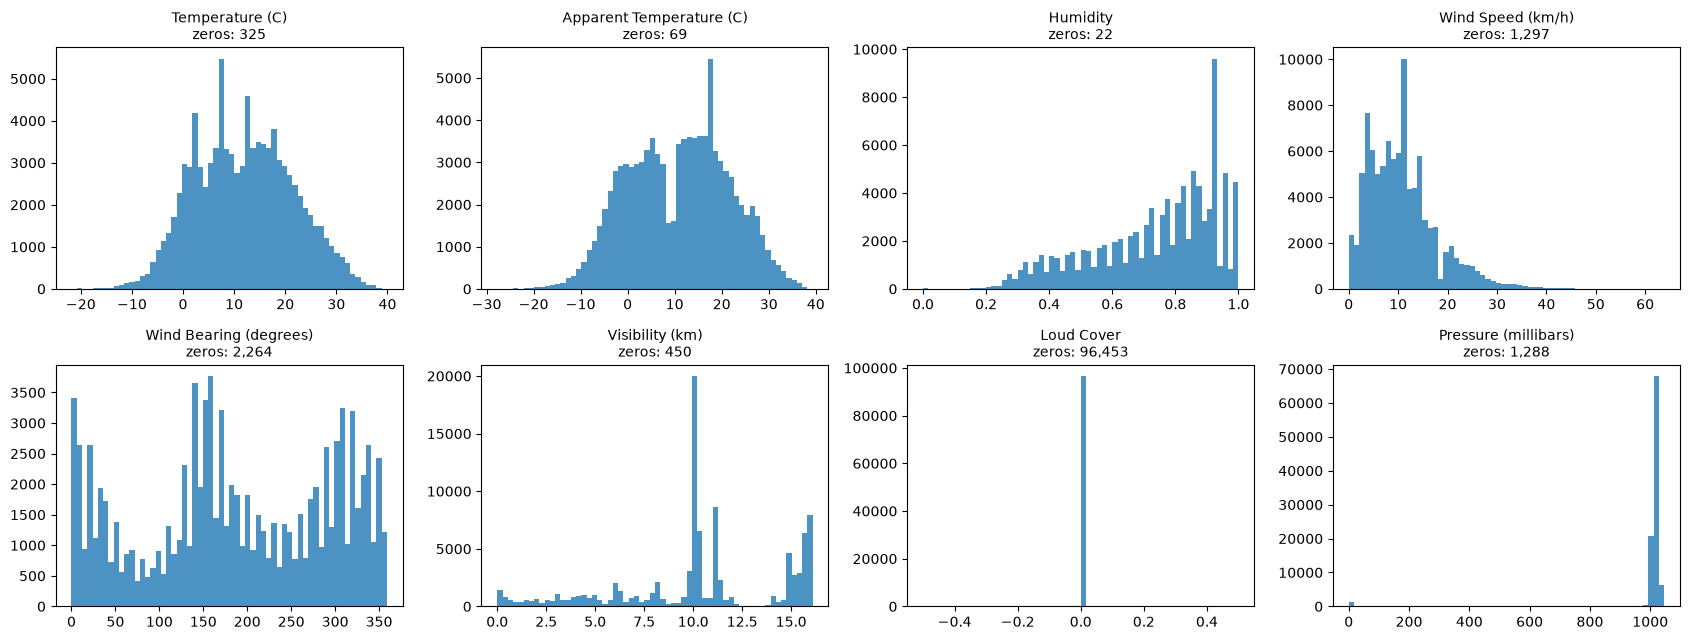

Most common visibility values (km): {9.98: 18290, 16.1: 7092, 15.83: 5683, 11.27: 4580}
Wind speed = 0 (calm): 1,297 hours | wind bearing = 0°: 2,264 hours


,count,mean,std,min,25%,50%,75%,max
Temperature (C),96453.0,11.93,9.55,-21.82,4.69,12.00,18.84,39.91
Apparent Temperature (C),96453.0,10.86,10.70,-27.72,2.31,12.00,18.84,39.34
Humidity,96453.0,0.73,0.20,0.00,0.60,0.78,0.89,1.00
Wind Speed (km/h),96453.0,10.81,6.91,0.00,5.83,9.97,14.14,63.85
Wind Bearing (degrees),96453.0,187.51,107.38,0.00,116.00,180.00,290.00,359.00
Visibility (km),96453.0,10.35,4.19,0.00,8.34,10.05,14.81,16.10
Loud Cover,96453.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Pressure (millibars),96453.0,1003.24,116.97,0.00,1011.90,1016.45,1021.09,1046.38


In [5]:
fig, axes = plt.subplots(2, 4, figsize=(17, 6.5))
for ax, col in zip(axes.ravel(), numeric):
    ax.hist(raw[col], bins=60, color="tab:blue", alpha=0.8)
    ax.set_title(f"{col}\nzeros: {(raw[col] == 0).sum():,}", fontsize=10)
plt.tight_layout(); plt.show()

print("Most common visibility values (km):", raw["Visibility (km)"].round(2).value_counts().head(4).to_dict())
print(f"Wind speed = 0 (calm): {(raw['Wind Speed (km/h)'] == 0).sum():,} hours | "
      f"wind bearing = 0°: {(raw['Wind Bearing (degrees)'] == 0).sum():,} hours")
raw[numeric].describe().T.round(2)

- **Issue 5 – impossible zeros.** `Pressure` is 0 mbar in **1,288 hours**, while real values sit around 1,000–1,045 mbar. `Humidity` is exactly 0 in **22 hours**. Both are sensor failures, i.e. missing data, so we interpolate them in time.
- **Temperature** ranges from −22 to 40 °C with a broad spread (winter to summer). It's the target and our most important input.
- **Visibility** has a hard maximum of **16.1 km (= 10 miles)**, and most readings fall on a few values (9.98, 15.83, 16.1 km). It was probably measured in miles and rounded. It's still a valid measurement, so we keep it and check later whether it helps. Visibility 0 (450 hours) is possible in dense fog, so we keep those too.
- **Wind bearing** is an angle from 0° to 359°. As a plain number, 359° and 1° look far apart even though they're neighbours, and the bearing means nothing when the wind is calm (speed 0). So we turn speed + bearing into **east/north wind components** (§4).
- **Humidity = 1.0** (2,890 hours) is plausible: saturated air, e.g. fog. We keep it.

### 2.3 Text columns – values

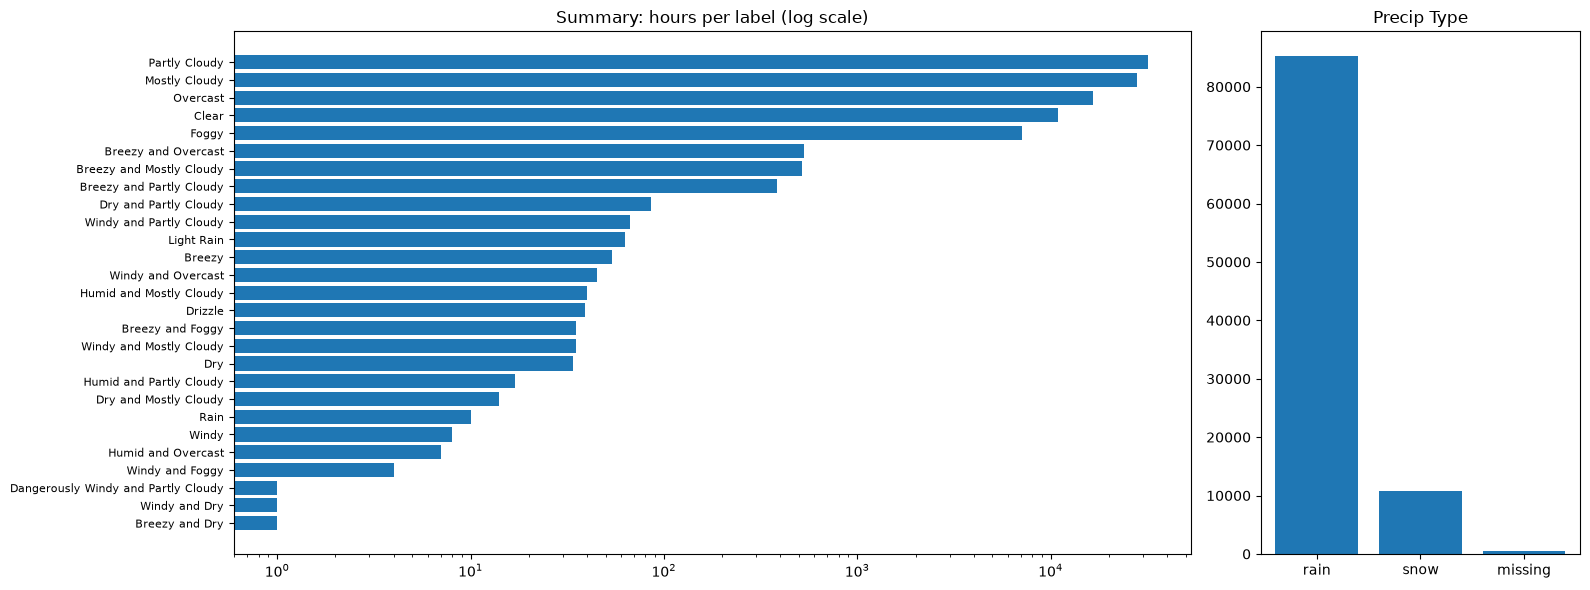

Daily Summary: 214 different sentences; different sentences within one day: 1 (always the same for all hours of a day)
Daily Summary
Mostly cloudy throughout the day.         20085
Partly cloudy throughout the day.          9981
Partly cloudy until night.                 6169
Partly cloudy starting in the morning.     5184
Foggy in the morning.                      4201


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [3, 1]})
vc = raw["Summary"].value_counts()
ax[0].barh(vc.index[::-1], vc.values[::-1]); ax[0].set_xscale("log")
ax[0].set_title("Summary: hours per label (log scale)"); ax[0].tick_params(axis="y", labelsize=8)
pt = raw["Precip Type"].fillna("missing").value_counts()
ax[1].bar(pt.index, pt.values); ax[1].set_title("Precip Type")
plt.tight_layout(); plt.show()

per_day = raw.assign(day=raw["Formatted Date"].str.slice(0, 10)).groupby("day")["Daily Summary"].nunique()
print(f"Daily Summary: {raw['Daily Summary'].nunique()} different sentences; "
      f"different sentences within one day: {per_day.max()} (always the same for all hours of a day)")
print(raw["Daily Summary"].value_counts().head(5).to_string())

- **`Summary`** is dominated by five cloud/fog labels (Partly Cloudy, Mostly Cloudy, Overcast, Clear, Foggy), which cover 98 % of hours. The rest are combinations with *Breezy/Windy/Dry/Humid* and a few rain labels. The useful content is **cloud cover, fog and wind**, so we extract those as numbers (§4).
- **`Precip Type`** has only `rain`, `snow` or missing. Almost every hour has a value, even clear ones, so it's suspicious; see §2.5.
- **`Daily Summary`** is **one sentence per day**, repeated for all its hours (e.g. "Mostly cloudy throughout the day."). We can only use it for the past days, never for the day we predict, and only via text methods (a bag of words, Class 2).

### 2.4 The time axis

In [7]:
t = pd.to_datetime(raw["Formatted Date"], utc=True)
print("UTC offsets in the timestamps:", raw["Formatted Date"].str.slice(-5).value_counts().to_dict())
print("File sorted by time:", t.is_monotonic_increasing)
print("Fully duplicated rows:", raw.duplicated().sum(), "| duplicated timestamps:", t.duplicated().sum(),
      "| on the dates:", sorted(set(raw.loc[t.duplicated(keep=False), "Formatted Date"].str.slice(0, 10))))
gaps = t.drop_duplicates().sort_values().diff().value_counts()
print("Time steps between readings:", {str(k): v for k, v in gaps.items()})
local = t.drop_duplicates().dt.tz_convert(CONFIG["data"]["timezone"])
hours_per_day = local.dt.date.value_counts()
print("Hours per local day:", hours_per_day.value_counts().sort_index().to_dict(),
      "| incomplete:", hours_per_day[hours_per_day < 23].to_dict())
print("Rows per year:", local.dt.year.value_counts().sort_index().to_dict())

UTC offsets in the timestamps: {'+0200': 56469, '+0100': 39984}
File sorted by time: False
Fully duplicated rows: 24 | duplicated timestamps: 24 | on the dates: ['2010-08-02']
Time steps between readings: {'0 days 01:00:00': 96427, '0 days 04:00:00': 1}
Hours per local day: {21: 1, 23: 11, 24: 3995, 25: 11} | incomplete: {datetime.date(2014, 7, 14): 21}
Rows per year: {2006: 8760, 2007: 8760, 2008: 8784, 2009: 8760, 2010: 8760, 2011: 8760, 2012: 8784, 2013: 8760, 2014: 8757, 2015: 8760, 2016: 8784}


`load_clean` applied the fixes from §2.1–2.6:
- converted mixed UTC offsets to local time (Issue 1) and sorted the rows (Issue 2)
- dropped the 24 duplicated rows (Issue 3)
- interpolated the impossible zeros in pressure and humidity (Issue 5)
- dropped `Apparent Temperature` (forbidden), `Loud Cover` (constant, Issue 4) and the raw timestamp text

`Precip Type` (Issue 6) and the rain labels (Issue 8) are left in the table but never used as features; the missing hours (Issue 7) are interpolated when the hourly input is built (§5).

### 2.5 Redundant and forbidden columns

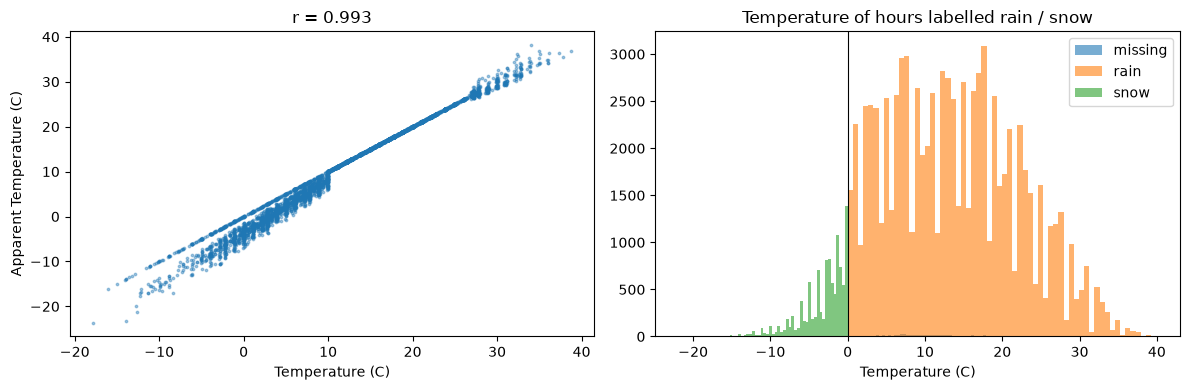

hours with,temperature > 0 °C,temperature ≤ 0 °C
Precip Type,,
missing,517,0
rain,85224,0
snow,0,10712


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
s = raw.sample(5000, random_state=0)
ax[0].scatter(s["Temperature (C)"], s["Apparent Temperature (C)"], s=3, alpha=0.4)
ax[0].set_xlabel("Temperature (C)"); ax[0].set_ylabel("Apparent Temperature (C)")
ax[0].set_title(f"r = {raw['Temperature (C)'].corr(raw['Apparent Temperature (C)']):.3f}")
for name, g in raw.groupby(raw["Precip Type"].fillna("missing")):
    ax[1].hist(g["Temperature (C)"], bins=60, alpha=0.6, label=name)
ax[1].axvline(0, color="k", lw=0.8); ax[1].legend(); ax[1].set_xlabel("Temperature (C)")
ax[1].set_title("Temperature of hours labelled rain / snow")
plt.tight_layout(); plt.show()
pd.crosstab(raw["Precip Type"].fillna("missing"), np.where(raw["Temperature (C)"] <= 0, "temperature ≤ 0 °C", "temperature > 0 °C"),
            rownames=["Precip Type"], colnames=["hours with"])

- **`Apparent Temperature`** (the "feels like" temperature) is almost a copy of the temperature (r = 0.993). The brief forbids using it, and it would also be close to cheating. We drop it right at loading so it can't leak into anything.
- **Issue 6 – `Precip Type` is not precipitation.** The table shows a perfect split: **every** `snow` hour is at ≤ 0 °C and **every** `rain` hour above 0 °C. The column is just "is it freezing?", so it repeats information we already have from the temperature. We drop it.

### 2.6 Rare labels over time

In [9]:
year = t.dt.tz_convert(CONFIG["data"]["timezone"]).dt.year.rename("year")
rare = vc[vc < 1000].index
rare_by_year = pd.crosstab(raw.loc[raw["Summary"].isin(rare), "Summary"], year[raw["Summary"].isin(rare)])
rain = raw["Summary"].str.contains("Rain|Drizzle")
print("Hours with a rain label per year:", year[rain].value_counts().sort_index().to_dict())
rare_by_year

Hours with a rain label per year: {2012: 22, 2016: 90}


year,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016
Summary,,,,,,,,,,,
Breezy,2,11,3,6,2,3,4,1,13,8,1
Breezy and Dry,0,0,0,0,0,0,1,0,0,0,0
Breezy and Foggy,7,0,0,0,2,0,14,10,1,1,0
Breezy and Mostly Cloudy,40,38,68,71,39,29,61,55,44,61,10
Breezy and Overcast,31,31,31,88,52,25,46,67,69,39,49
Breezy and Partly Cloudy,32,57,45,51,31,34,50,30,9,32,15
Dangerously Windy and Partly Cloudy,0,1,0,0,0,0,0,0,0,0,0
Drizzle,0,0,0,0,0,0,5,0,0,0,34
Dry,0,14,3,2,0,0,14,1,0,0,0


- **Issue 8 – rain labels exist almost only in the test year.** "Light Rain", "Rain" and "Drizzle" appear in **22 hours of 2012** and **90 hours of 2016**, and never in any other year. With only 22 hours in all the training years, a model can't learn what rain means. It would also see rain in 2016 far more often than ever in training. So we **don't use a rain feature**. (We first noticed this when one K-fold fold blew up: with 2012 held out, the training data had no rain at all, so its standard deviation was 0. Scaling now handles such cases safely; see `safe_std`.)
- **"Dry"** and **"Humid"** labels are rare too, and concentrated in a few years (e.g. "Dry and Mostly Cloudy" only in 2012). We don't build features from them. *Breezy/Windy* labels appear in every year, so the **windy** flag is safe to use.

### 2.7 Decision: what we keep, transform or drop

| Column | Decision | Reason (evidence) |
|---|---|---|
| `Formatted Date` | **transform** → timestamp in local time; hour of day and day of year | mixed UTC offsets, unsorted, duplicates (§2.4) |
| `Temperature (C)` | **keep** (target and input) | the variable we predict; strongest signal (§3) |
| `Apparent Temperature (C)` | **drop** | forbidden by the brief; a near copy of temperature (r = 0.993, §2.5) |
| `Humidity` | **keep**, zeros → interpolated; plus **dew point** derived with temperature | 22 impossible zeros (§2.2); moisture affects night-time cooling |
| `Wind Speed (km/h)` | **keep** | most informative single variable for tomorrow's change (§3) |
| `Wind Bearing (degrees)` | **transform** → east/north wind components (with speed) | an angle: 359° ≈ 1°, meaningless at calm (§2.2) |
| `Visibility (km)` | **keep** (checked later) | valid but coarse, capped at 16.1 km; weak signal (§3, ablation §7) |
| `Loud Cover` | **drop** | a single value (0) in every row (§2.1) |
| `Pressure (millibars)` | **keep**, zeros → interpolated; plus **daily pressure change** | 1,288 impossible zeros (§2.2); pressure trends signal fronts (§3) |
| `Precip Type` | **drop** | exactly "temperature ≤ 0 °C" (§2.5) |
| `Summary` | **transform** → cloudiness (0–3), fog flag, windy flag; **no rain flag** | 27 labels, 98 % about clouds/fog (§2.3); rain labels only in 2012/2016 (§2.6) |
| `Daily Summary` | **only as an optional text experiment** | one sentence per day (§2.3); tested as a bag of words in §7 and **rejected** (it made results worse) |

### 2.8 Cleaning – applying the decisions

`load_clean` reads the file, checks its hash and applies the decisions above.

In [10]:
RENAME = {
    "Temperature (C)": "temp", "Humidity": "humidity", "Wind Speed (km/h)": "wind_speed",
    "Wind Bearing (degrees)": "wind_bearing", "Visibility (km)": "visibility",
    "Pressure (millibars)": "pressure", "Precip Type": "precip_type",
    "Summary": "summary", "Daily Summary": "daily_summary",
}


def load_clean(cfg, verbose=False):
    """Read the CSV, check its hash and fix the data issues found during exploration."""
    path = Path(cfg["data"]["path"])
    sha = hashlib.sha256(path.read_bytes()).hexdigest()
    assert sha == cfg["data"]["sha256"], f"Dataset changed! hash = {sha}"
    df = pd.read_csv(path)
    log = {}
    # Mixed +01:00/+02:00 offsets (daylight saving time): parse as UTC, then convert to local time.
    df["time"] = pd.to_datetime(df["Formatted Date"], utc=True).dt.tz_convert(cfg["data"]["timezone"])
    log["sorted_in_file"] = bool(df["time"].is_monotonic_increasing)
    df = df.sort_values("time")
    log["duplicate_timestamps"] = int(df["time"].duplicated().sum())
    df = df.drop_duplicates(subset="time").set_index("time")
    log["loud_cover_unique"] = df["Loud Cover"].unique().tolist()
    log["pressure_zero_rows"] = int((df["Pressure (millibars)"] == 0).sum())
    log["humidity_zero_rows"] = int((df["Humidity"] == 0).sum())
    for col in ["Pressure (millibars)", "Humidity"]:   # 0 mbar / 0 % humidity = sensor fault
        df[col] = df[col].replace(0, np.nan).interpolate(method="time")
    # The forbidden column is dropped immediately so it can't leak anywhere.
    df = df.drop(columns=["Apparent Temperature (C)", "Loud Cover", "Formatted Date"]).rename(columns=RENAME)
    if verbose:
        for k, v in log.items():
            print(f"{k}: {v}")
    return df

In [11]:
df = load_clean(CONFIG, verbose=True)
print(df.shape, "| from", df.index.min(), "to", df.index.max())

sorted_in_file: False
duplicate_timestamps: 24
loud_cover_unique: [0.0]
pressure_zero_rows: 1288
humidity_zero_rows: 22
(96429, 9) | from 2006-01-01 00:00:00+01:00 to 2016-12-31 23:00:00+01:00


- **Issue 1 – mixed time zones.** Timestamps switch between `+0100` and `+0200` (daylight saving). We parse to UTC and convert to `Europe/Budapest`, so "a day" is a real local calendar day. Local days have 23 or 25 hours at the DST switches. For the hourly model input we use a regular UTC hourly grid instead (§4).
- **Issue 2 – the file is not sorted by time.** Sorting is required before any windowing.
- **Issue 3 – 24 duplicated rows.** The whole of 2010-08-02 appears twice; we drop the duplicates.
- **Issue 4 – `Loud Cover` is always 0**, so it carries no information and is dropped.
- **Issue 5 – 1,288 hours with pressure = 0 mbar** and **22 with humidity = 0**. Both are impossible values, i.e. missing data. We interpolate them in time.
- **Forbidden column:** `Apparent Temperature (C)` is dropped inside `load_clean`, so it can't leak into anything later. Its correlation with temperature is 0.99, so using it would be close to cheating.

## 3. Exploration

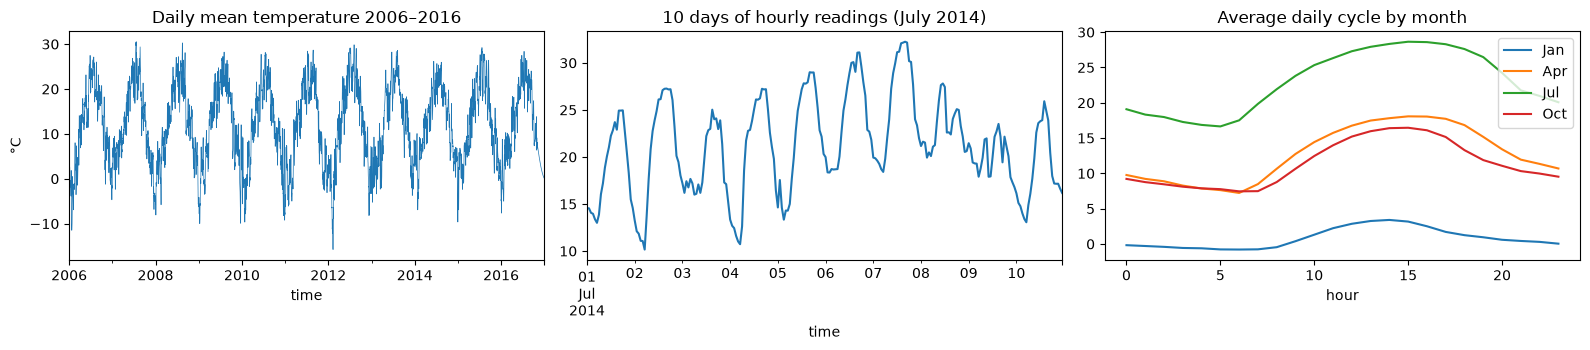

In [12]:
daily_temp = df["temp"].resample("D").mean()
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
daily_temp.plot(ax=ax[0], lw=0.5); ax[0].set_title("Daily mean temperature 2006–2016"); ax[0].set_ylabel("°C")
df["temp"].loc["2014-07-01":"2014-07-10"].plot(ax=ax[1]); ax[1].set_title("10 days of hourly readings (July 2014)")
by_hour = df.groupby([df.index.month, df.index.hour])["temp"].mean().unstack(0)
by_hour[[1, 4, 7, 10]].plot(ax=ax[2]); ax[2].set_title("Average daily cycle by month"); ax[2].set_xlabel("hour")
ax[2].legend(["Jan", "Apr", "Jul", "Oct"])
plt.tight_layout(); plt.show()

**Conclusions**
- **Yearly cycle** (about 25 °C between winter and summer). It's fully predictable from the calendar, so the model gets the day of the year of the predicted day as a feature. This isn't leakage: the date is always known in advance.
- **Daily cycle** (about 5–12 °C between night and afternoon, larger in summer). A daily average hides this shape and the most recent hours. That motivated trying the **hourly** sequence as input, which turned out to be the biggest single improvement (§7).

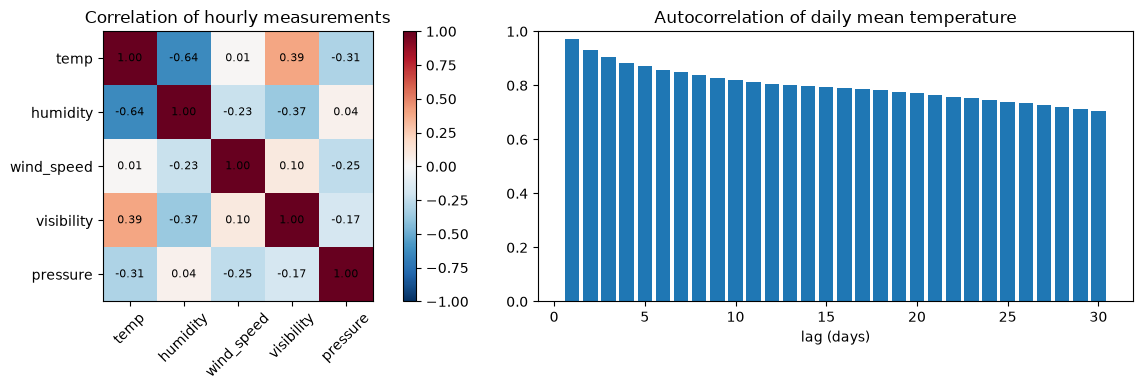

Day-to-day change of the daily mean: mean |change| = 1.63 °C, std = 2.16 °C, largest drop = -11.0 °C, largest rise = 11.3 °C


In [13]:
num = df[["temp", "humidity", "wind_speed", "visibility", "pressure"]]
corr = num.corr()
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
im = ax[0].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); fig.colorbar(im, ax=ax[0])
ax[0].set_xticks(range(len(corr)), corr.columns, rotation=45); ax[0].set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax[0].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax[0].set_title("Correlation of hourly measurements")
lags = range(1, 31)
ax[1].bar(lags, [daily_temp.autocorr(l) for l in lags])
ax[1].set_title("Autocorrelation of daily mean temperature"); ax[1].set_xlabel("lag (days)"); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

change = daily_temp.diff().dropna()
print(f"Day-to-day change of the daily mean: mean |change| = {change.abs().mean():.2f} °C, "
      f"std = {change.std():.2f} °C, largest drop = {change.min():.1f} °C, largest rise = {change.max():.1f} °C")

**Conclusions**
- Lag-1 autocorrelation ≈ 0.97: tomorrow is usually close to today. "Tomorrow = today" (**persistence**) is a strong baseline that every model must beat.
- Because tomorrow ≈ today, we also test predicting the **change** (tomorrow − today) instead of the absolute value (§7, stage *target*).
- Humidity is strongly anti-correlated with temperature. Pressure barely correlates with temperature directly, but pressure *changes* signal weather fronts, so we keep it and also compute its daily change.
- The daily mean usually changes by about 1.6 °C from one day to the next, but sometimes by up to 11 °C (cold fronts, sudden warm-ups). These jumps are the hardest days to predict (§10).

### Which variables say something about tomorrow? (training years only)

Correlation with tomorrow's mean is easy: today's temperature alone gives r = 0.97. The hard part is the **change** from today to tomorrow, so we measure each variable's relationship with it. We use the Pearson correlation *r* (linear) and the **mutual information** (MI, any kind of relationship; 0 = none). Only the training years 2006–2013 are used.

In [14]:
from sklearn.feature_selection import mutual_info_regression

rad = np.deg2rad(df["wind_bearing"])
hv = pd.DataFrame({
    "temperature": df["temp"], "humidity": df["humidity"], "visibility": df["visibility"],
    "pressure": df["pressure"], "wind speed": df["wind_speed"],
    "wind bearing (raw angle)": df["wind_bearing"],
    "wind east component": df["wind_speed"] * np.sin(rad), "wind north component": df["wind_speed"] * np.cos(rad),
    "snow label (Precip Type)": (df["precip_type"] == "snow").astype(float),
})
day = hv.resample("D").mean()
day["pressure change during the day"] = df["pressure"].resample("D").last() - df["pressure"].resample("D").first()
day.index = day.index.tz_localize(None)
tomorrow = day["temperature"].shift(-1)
change = tomorrow - day["temperature"]
m = (day.index <= CONFIG["data"]["train_end"]) & tomorrow.notna()
signal = pd.DataFrame([{
    "variable (today)": c,
    "r with tomorrow's mean": day.loc[m, c].corr(tomorrow[m]),
    "r with tomorrow's change": day.loc[m, c].corr(change[m]),
    "MI with tomorrow's change": mutual_info_regression(day.loc[m, [c]], change[m], random_state=0)[0],
} for c in day.columns]).sort_values("MI with tomorrow's change", ascending=False)
signal.round(3)

,variable (today),r with tomorrow's mean,r with tomorrow's change,MI with tomorrow's change
4,wind speed,-0.181,-0.216,0.077
7,wind north component,-0.056,-0.135,0.056
5,wind bearing (raw angle),0.023,-0.076,0.041
0,temperature,0.970,-0.123,0.041
9,pressure change during the day,-0.089,-0.167,0.032
8,snow label (Precip Type),-0.666,0.114,0.031
6,wind east component,0.027,0.122,0.028
3,pressure,-0.278,0.184,0.024
2,visibility,0.563,-0.094,0.006
1,humidity,-0.598,0.046,0.000


**Conclusions**
- **No single variable predicts the change well** (all |r| ≤ 0.22). A useful model has to **combine** several variables, possibly non-linearly, which is what a neural network is good at.
- The most informative variables for the change are **wind speed**, the **north–south wind component** (northerly wind brings cold air), the **pressure change** and the **pressure level**. These are exactly the weather-front signals, so we keep them.
- **Visibility** and **humidity alone** carry almost no information about the change. Humidity is still kept, because combined with temperature it gives the dew point (moisture), and the ablation in §7 shows that moisture helps. Visibility also didn't help in the ablation.
- The **snow label** only correlates with tomorrow's mean through temperature (r = −0.67), which confirms the drop decision in §2.5.
- The **raw wind angle** carries some information (MI 0.041) but almost no linear correlation (r = −0.08). What matters is where the wind comes from, and a plain angle encodes that badly (359° and 1° look far apart). The east/north components express the same information continuously; the north component alone reaches MI 0.056.

## 4. Feature engineering

**Hourly features** (computed for every hour; `hourly_features` below):

| Feature | Why |
|---|---|
| temperature, humidity, visibility, pressure | raw measurements (standardised) |
| **dew point** (Magnus formula) | combines temperature and humidity into the actual amount of moisture in the air. Moist air cools less at night. |
| wind speed + **wind u/v components** | the wind direction is an angle (359° and 1° are neighbours), so it's turned into east/north vectors |
| **cloudiness, fog, windy** | numeric versions of the `Summary` text; clouds limit daytime heating and night-time cooling. No rain flag (Issue 8). |
| **hour of day** (sin, cos) | lets the model know where in the daily cycle each reading is |

**Daily features** (one row per day; `daily_table` below): mean, min and max temperature, the **last-hour temperature**, the **temperature trend over the last 6 hours**, mean humidity, dew point, visibility, pressure, **pressure change during the day**, wind, and cloudiness/fog/wind fractions.

**Calendar:** the day of the year of the *predicted* day as sin/cos, so 31 Dec and 1 Jan are neighbours.

In [15]:
CLOUD = {"Partly Cloudy": 1, "Mostly Cloudy": 2, "Overcast": 3, "Clear": 0}


def _cloudiness(s):
    for name, v in CLOUD.items():   # "Partly/Mostly Cloudy" checked before plain words
        if name in s:
            return v
    return np.nan


def hourly_features(df):
    """Numeric hourly features (used both for daily aggregates and the hourly model input)."""
    h = pd.DataFrame(index=df.index)
    h["temp"] = df["temp"]
    h["humidity"] = df["humidity"]
    # Dew point (Magnus formula): the temperature at which air becomes saturated.
    # Combines temperature and humidity into the amount of moisture in the air.
    a, b = 17.62, 243.12
    gamma = np.log(df["humidity"].clip(lower=0.01)) + a * df["temp"] / (b + df["temp"])
    h["dew_point"] = b * gamma / (a - gamma)
    h["visibility"] = df["visibility"]
    h["pressure"] = df["pressure"]
    rad = np.deg2rad(df["wind_bearing"])        # angle -> vector, so 359° and 1° are close
    h["wind_speed"] = df["wind_speed"]
    h["wind_u"] = df["wind_speed"] * np.sin(rad)
    h["wind_v"] = df["wind_speed"] * np.cos(rad)
    h["cloudiness"] = df["summary"].map(_cloudiness)
    h["cloudiness"] = h["cloudiness"].fillna(h["cloudiness"].rolling(6, min_periods=1).mean()).fillna(1.5)
    h["fog"] = df["summary"].str.contains("Fog").astype(float)
    h["windy"] = df["summary"].str.contains("Breezy|Windy").astype(float)
    # No "rain" flag: rain labels appear only in 2012 (22 h) and 2016 (90 h) - see Issue 8.
    return h

In [16]:
def daily_table(df, h):
    """One row per local calendar day."""
    g = h.resample("D")
    d = pd.DataFrame({
        "temp_mean": g["temp"].mean(), "temp_min": g["temp"].min(), "temp_max": g["temp"].max(),
        "temp_last": g["temp"].last(),
        # temperature change over the last 6 hours of the day (evening trend)
        "temp_trend_6h": g["temp"].last() - h["temp"].resample("D").apply(lambda s: s.iloc[-7] if len(s) >= 7 else s.iloc[0]),
        "humidity": g["humidity"].mean(), "dew_point": g["dew_point"].mean(),
        "visibility": g["visibility"].mean(),
        "pressure": g["pressure"].mean(), "pressure_change": g["pressure"].last() - g["pressure"].first(),
        "wind_speed": g["wind_speed"].mean(), "wind_u": g["wind_u"].mean(), "wind_v": g["wind_v"].mean(),
        "cloudiness": g["cloudiness"].mean(), "fog": g["fog"].mean(), "windy": g["windy"].mean(),
    })
    d["daily_summary"] = df["daily_summary"].resample("D").first()
    d.index = d.index.tz_localize(None).normalize()
    num = d.columns.drop("daily_summary")
    d[num] = d[num].interpolate()
    d["daily_summary"] = d["daily_summary"].ffill()
    return d


FEATURE_GROUPS = {
    "temperature": ["temp_mean", "temp_min", "temp_max", "temp_last", "temp_trend_6h"],
    "moisture": ["humidity", "dew_point"],
    "visibility": ["visibility"],
    "pressure": ["pressure", "pressure_change"],
    "wind": ["wind_speed", "wind_u", "wind_v"],
    "sky": ["cloudiness", "fog", "windy"],
}


HOURLY_COLS = ["temp", "humidity", "dew_point", "visibility", "pressure",
               "wind_speed", "wind_u", "wind_v", "cloudiness", "fog", "windy"]

## 5. Windows, split and normalisation

- **Sample:** for a target day *t*, the inputs are days *t-3, t-2, t-1* (as 3 daily rows and/or the 72 hourly rows before local midnight) and the output is the mean temperature of day *t*.
- **Split by time, not at random.** Neighbouring days are nearly identical, so a random split would leak test information into training (temporal leakage, Class 1). We use:
  train **2006–2013** · validation **2014–2015** (all model choices) · test **2016** (used **once**, at the very end).
- **Normalisation** statistics (mean/std) come **from the training rows only**. The **target is scaled too** (`regression.ipynb`: "we can simply scale the outputs and then scale them back"). Predictions are converted back to °C before computing errors.
- **Metric: MAE in °C** – "on average we are X degrees off". **Loss: MSE** (Class 2 recommendation for regression).

`Dataset` builds every sample at once: the 3 daily rows, the 72 hourly rows, the calendar values, the 3 `Daily Summary` sentences and the target. `mask()` returns which samples belong to train, validation, test or a block of years (for K-fold).

In [17]:
class Dataset:
    """All model inputs for every target day, plus the time-based split.

    Sample for target day t: days t-3..t-1 (daily rows, 72 hourly rows, 3 daily summaries)
    + day-of-year of t  ->  mean temperature of day t.
    """

    def __init__(self, cfg, verbose=False):
        self.cfg = cfg
        df = load_clean(cfg, verbose=verbose)
        self.hourly_raw = df
        h = hourly_features(df)
        self.daily = daily_table(df, h)
        W = cfg["data"]["window_days"]

        # Regular UTC hourly grid (no DST jumps); fill the few missing hours by interpolation.
        hu = h.tz_convert("UTC")
        hu = hu.reindex(pd.date_range(hu.index.min(), hu.index.max(), freq="h")).interpolate()
        hour_local = hu.index.tz_convert(cfg["data"]["timezone"]).hour
        hu["hour_sin"] = np.sin(2 * np.pi * hour_local / 24)
        hu["hour_cos"] = np.cos(2 * np.pi * hour_local / 24)
        self.hourly_cols = HOURLY_COLS + ["hour_sin", "hour_cos"]
        hv = hu[self.hourly_cols].to_numpy("float32")
        h_index = hu.index

        days = self.daily.index
        self.dates = days[W:]
        all_feats = [c for g in FEATURE_GROUPS.values() for c in g]
        dv = self.daily[all_feats].to_numpy("float32")
        self.daily_cols = all_feats
        self.X_daily = np.stack([dv[t - W:t] for t in range(W, len(days))])

        # 72 hours before local midnight of the target day
        midnights = (self.dates.tz_localize(cfg["data"]["timezone"]).tz_convert("UTC"))
        pos = h_index.get_indexer(midnights)
        assert (pos >= W * 24).all() and (pos >= 0).all()
        self.X_hourly = np.stack([hv[p - W * 24:p] for p in pos])

        doy = self.dates.dayofyear.to_numpy()
        self.X_cal = np.stack([np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)], 1).astype("float32")
        texts = self.daily["daily_summary"].to_numpy()
        self.texts = np.array([" | ".join(texts[t - W:t]) for t in range(W, len(days))])
        self.y = self.daily["temp_mean"].to_numpy("float32")[W:]
        self.last_mean = self.X_daily[:, -1, all_feats.index("temp_mean")]
        # Extra targets for the multi-output variants (§7b): next-day min/max and the 24 hourly temperatures.
        self.y_min = self.daily["temp_min"].to_numpy("float32")[W:]
        self.y_max = self.daily["temp_max"].to_numpy("float32")[W:]
        self.last_min = self.X_daily[:, -1, all_feats.index("temp_min")]
        self.last_max = self.X_daily[:, -1, all_feats.index("temp_max")]
        temp_h = np.pad(hv[:, self.hourly_cols.index("temp")], (0, 24), mode="edge")
        self.y_hourly = np.stack([temp_h[p:p + 24] for p in pos])

    def mask(self, part, years=None):
        d, c = self.dates, self.cfg["data"]
        if part == "train":
            return d <= c["train_end"]
        if part == "val":
            return (d > c["train_end"]) & (d <= c["val_end"])
        if part == "test":
            return d > c["val_end"]
        if part == "trainval":
            return d <= c["val_end"]
        if part == "years":
            return np.isin(d.year, years)
        raise ValueError(part)

In [18]:
ds = Dataset(CONFIG)
print("samples:", len(ds.y))
print("daily input  :", ds.X_daily.shape[1:], "=", ds.X_daily.shape[1], "days ×", len(ds.daily_cols), "features")
print("hourly input :", ds.X_hourly.shape[1:], "=", ds.X_hourly.shape[1], "hours ×", len(ds.hourly_cols), "features")
print("calendar     :", ds.X_cal.shape[1:])
print("text example :", ds.texts[0])
ds.daily.drop(columns="daily_summary").head(3).round(2)

samples: 4015
daily input  : (3, 16) = 3 days × 16 features
hourly input : (72, 13) = 72 hours × 13 features
calendar     : (2,)
text example : Mostly cloudy throughout the day. | Overcast throughout the day. | Mostly cloudy throughout the day.


,temp_mean,temp_min,temp_max,temp_last,temp_trend_6h,humidity,dew_point,visibility,pressure,pressure_change,wind_speed,wind_u,wind_v,cloudiness,fog,windy
time,,,,,,,,,,,,,,,,
2006-01-01,3.87,0.58,7.44,5.42,-0.48,0.82,1.03,11.11,1012.28,-7.02,21.37,13.11,-16.80,2.25,0.0,0.0
2006-01-02,5.42,1.69,7.51,1.69,-4.24,0.84,2.94,8.96,1010.13,5.67,17.55,5.03,-13.41,2.96,0.0,0.0
2006-01-03,2.32,1.67,2.90,2.20,-0.58,0.90,0.81,9.01,1020.80,8.78,8.42,-6.23,-3.10,2.58,0.0,0.0


In [19]:
for part in ["train", "val", "test"]:
    m = ds.mask(part)
    print(f"{part:5s}: {m.sum():5d} samples  {ds.dates[m].min().date()} → {ds.dates[m].max().date()}")

train:  2919 samples  2006-01-04 → 2013-12-31
val  :   730 samples  2014-01-01 → 2015-12-31
test :   366 samples  2016-01-01 → 2016-12-31


### Scaling, model and training code

- **`Prepared`** fits all scaling on the training rows of one experiment only: inputs and the target, as in `regression.ipynb`. It can drop feature groups (for the ablation) and converts predictions back to °C. With `target: delta` it also adds back today's mean.
- **`build_model`** builds a functional-API model (Class 3) from a parameter dictionary. It uses one branch per input (hourly / daily: flatten, GRU, LSTM or Conv1D), then dense layers with optional dropout and L2, and `Dense(1)` with no activation, for regression.
- **`train_eval`** trains one model with a fixed seed. Given a validation set, it uses early stopping (and optionally ReduceLROnPlateau) and returns the validation MAE in °C. Without one, it trains for a fixed number of epochs (the final retraining).

In [20]:
class Prepared:
    """Scales inputs/target with statistics from the training rows only."""

    def __init__(self, ds, train_mask, p):
        self.ds, self.p = ds, p
        cols = [c for g, cs in FEATURE_GROUPS.items() if g not in p.get("drop_groups", []) for c in cs]
        self.col_idx = [ds.daily_cols.index(c) for c in cols]
        hcols = [c for c in ds.hourly_cols if not _hourly_in_dropped(c, p.get("drop_groups", []))]
        self.hcol_idx = [ds.hourly_cols.index(c) for c in hcols]
        Xd = ds.X_daily[train_mask][:, :, self.col_idx]
        Xh = ds.X_hourly[train_mask][:, :, self.hcol_idx]
        self.mu_d, self.sd_d = Xd.reshape(-1, Xd.shape[-1]).mean(0), safe_std(Xd.reshape(-1, Xd.shape[-1]))
        self.mu_h, self.sd_h = Xh.reshape(-1, Xh.shape[-1]).mean(0), safe_std(Xh.reshape(-1, Xh.shape[-1]))
        t = self._raw_target(train_mask)
        if t.ndim == 1:
            self.mu_y, self.sd_y = float(t.mean()), float(t.std())   # target scaling (Class 2, regression)
        else:                                                         # one scale per output column
            self.mu_y, self.sd_y = t.mean(0), t.std(0)
        if p.get("text"):
            self.vec = keras.layers.TextVectorization(max_tokens=300, output_mode="multi_hot")
            self.vec.adapt(ds.texts[train_mask])

    def _raw_target(self, m):
        ds, aux, delta = self.ds, self.p.get("aux", "none"), self.p["target"] == "delta"
        if aux == "minmax":      # next-day mean, min and max (relative to today's mean/min/max)
            y = np.stack([ds.y[m], ds.y_min[m], ds.y_max[m]], 1)
            return y - np.stack([ds.last_mean[m], ds.last_min[m], ds.last_max[m]], 1) if delta else y
        if aux == "hourly24":    # the 24 hourly temperatures of the next day (relative to today's mean)
            y = ds.y_hourly[m]
            return y - ds.last_mean[m][:, None] if delta else y
        y = ds.y[m]
        return y - ds.last_mean[m] if delta else y

    def inputs(self, m):
        ds, p, x = self.ds, self.p, {}
        if p["input"] in ("daily", "both"):
            x["daily"] = (ds.X_daily[m][:, :, self.col_idx] - self.mu_d) / self.sd_d
        if p["input"] in ("hourly", "both"):
            x["hourly"] = (ds.X_hourly[m][:, :, self.hcol_idx] - self.mu_h) / self.sd_h
        if p.get("calendar", True):
            x["cal"] = ds.X_cal[m]
        if p.get("text"):
            x["text"] = self.vec(ds.texts[m]).numpy().astype("float32")
        return x

    def target(self, m):
        return ((self._raw_target(m) - self.mu_y) / self.sd_y).astype("float32")

    def to_celsius(self, pred_scaled, m):
        aux = self.p.get("aux", "none")
        if aux == "none":
            pred = pred_scaled.ravel() * self.sd_y + self.mu_y
            return pred + self.ds.last_mean[m] if self.p["target"] == "delta" else pred
        pred = pred_scaled * self.sd_y + self.mu_y
        pred = pred[:, 0] if aux == "minmax" else pred.mean(1)   # the daily mean is what we evaluate
        return pred + self.ds.last_mean[m] if self.p["target"] == "delta" else pred


def safe_std(x):
    """Standard deviation per feature, but 1.0 for (almost) constant features. Dividing by a near-zero
    std would turn a rare non-zero value in validation/test into a huge input (see Issue 8)."""
    sd = x.std(0)
    return np.where(sd < 1e-3, 1.0, sd)


def _hourly_in_dropped(col, groups):
    owner = {"temp": "temperature", "humidity": "moisture", "dew_point": "moisture", "visibility": "visibility",
             "pressure": "pressure", "wind_speed": "wind", "wind_u": "wind", "wind_v": "wind",
             "cloudiness": "sky", "fog": "sky", "windy": "sky"}
    return owner.get(col) in groups

In [21]:
def build_model(p, shapes, seed):
    """Functional-API model (Class 3) with up to four inputs."""
    L = keras.layers
    init = lambda: keras.initializers.GlorotUniform(seed=seed)
    reg = keras.regularizers.l2(p["l2"]) if p.get("l2") else None
    ins, parts = [], []

    def seq_branch(name, arch, units):
        i = keras.Input(shape=shapes[name], name=name); ins.append(i)
        if arch == "flatten":
            return L.Flatten()(i)
        if arch == "conv1d":
            x = L.Conv1D(units, 5, activation="relu", padding="same", kernel_initializer=init())(i)
            x = L.MaxPooling1D(3)(x)
            x = L.Conv1D(units, 3, activation="relu", padding="same", kernel_initializer=init())(x)
            return L.GlobalAveragePooling1D()(x)
        if arch == "conv_gru":   # Conv1D summarises each 3-hour block (72 -> 24 steps), the GRU reads the result
            x = L.Conv1D(units, 3, activation="relu", padding="same", kernel_initializer=init())(i)
            x = L.MaxPooling1D(3)(x)
            return L.GRU(units, kernel_initializer=init(), seed=seed)(x)
        rnn = {"lstm": L.LSTM, "gru": L.GRU}[arch]
        if name == "hourly" and p.get("attention"):
            # Attention pooling: a learned weight for every hour, so the model can focus on the
            # most informative hours (e.g. the latest ones) instead of only the final GRU state.
            seq, state = rnn(units, kernel_initializer=init(), seed=seed, return_sequences=True,
                             return_state=True)(i)[:2]
            w = L.Softmax(axis=1)(L.Dense(1, kernel_initializer=init())(seq))
            context = L.Flatten()(L.Dot(axes=1)([w, seq]))
            return L.Concatenate()([context, state])
        layer = rnn(units, kernel_initializer=init(), seed=seed, dropout=p.get("rnn_dropout", 0.0))
        return (L.Bidirectional(layer) if p.get("bidirectional") else layer)(i)

    if p["input"] in ("daily", "both"):
        parts.append(seq_branch("daily", p["daily_arch"], p["units"]))
    if p["input"] in ("hourly", "both"):
        parts.append(seq_branch("hourly", p["hourly_arch"], p["units"]))
    for name in ("cal", "text"):
        if name in shapes:
            i = keras.Input(shape=shapes[name], name=name); ins.append(i)
            parts.append(L.Dense(16, activation="relu", kernel_initializer=init())(i) if name == "text" else i)
    x = parts[0] if len(parts) == 1 else L.Concatenate()(parts)
    for u in p["dense"]:
        x = L.Dense(u, activation="relu", kernel_initializer=init(), kernel_regularizer=reg)(x)
        if p.get("dropout"):
            x = L.Dropout(p["dropout"], seed=seed)(x)
    n_out = {"none": 1, "minmax": 3, "hourly24": 24}[p.get("aux", "none")]
    out = L.Dense(n_out, kernel_initializer=init())(x)   # regression: no activation
    return keras.Model(ins, out)

In [22]:
def train_eval(ds, p, seed, train_m, val_m=None, epochs=None, log_csv=None, return_model=False, keep_pred=False):
    """Train one model. With val_m: early stopping on it and MAE (°C) returned.
    Without val_m: train for a fixed number of epochs (final retraining on train+val)."""
    set_seed(seed)
    prep = Prepared(ds, train_m, p)
    xtr, ytr = prep.inputs(train_m), prep.target(train_m)
    shapes = {k: v.shape[1:] for k, v in xtr.items()}
    model = build_model(p, shapes, seed)
    loss = keras.losses.Huber(delta=1.0) if p.get("loss") == "huber" else "mse"
    model.compile(optimizer=keras.optimizers.Adam(p["lr"]), loss=loss, metrics=["mae"])
    cbs = []
    if log_csv:
        Path(log_csv).parent.mkdir(parents=True, exist_ok=True)
        cbs.append(keras.callbacks.CSVLogger(str(log_csv)))
    fit_kw = dict(epochs=epochs or p["epochs"], batch_size=p["batch_size"], verbose=0, shuffle=True)
    if val_m is not None:
        cbs.append(keras.callbacks.EarlyStopping(monitor="val_loss", patience=p["patience"], restore_best_weights=True))
        if p.get("reduce_lr"):
            cbs.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=max(2, p["patience"] // 3)))
        fit_kw["validation_data"] = (prep.inputs(val_m), prep.target(val_m))
    elif p.get("reduce_lr"):   # final retraining has no validation set: follow training loss instead
        cbs.append(keras.callbacks.ReduceLROnPlateau(monitor="loss", factor=0.5, patience=max(2, p["patience"] // 3)))
    hist = model.fit(xtr, ytr, callbacks=cbs, **fit_kw)
    res = {"epochs_run": len(hist.history["loss"])}
    if val_m is not None:
        res["best_epoch"] = int(np.argmin(hist.history["val_loss"]) + 1)
        pred = prep.to_celsius(model.predict(prep.inputs(val_m), verbose=0, batch_size=1024), val_m)
        res["val_mae"] = float(np.mean(np.abs(pred - ds.y[val_m])))
        if keep_pred:
            res["val_pred"] = pred
    if return_model:
        return res, model, prep, hist
    return res


def predict_celsius(model, prep, m):
    return prep.to_celsius(model.predict(prep.inputs(m), verbose=0, batch_size=1024), m)

## 6. Baselines without learning

In [23]:
va, tr = ds.mask("val"), ds.mask("train")
clim = (pd.Series(ds.y[tr], index=ds.dates[tr].dayofyear).groupby(level=0).mean()
        .reindex(range(1, 367)).interpolate().rolling(15, center=True, min_periods=1).mean())
baselines = {
    "persistence (tomorrow = today)": np.abs(ds.last_mean[va] - ds.y[va]).mean(),
    "climatology (average for this day of year)": np.abs(clim.loc[ds.dates[va].dayofyear].to_numpy() - ds.y[va]).mean(),
}
for k, v in baselines.items():
    print(f"validation MAE {v:.3f} °C – {k}")

validation MAE 1.525 °C – persistence (tomorrow = today)
validation MAE 2.852 °C – climatology (average for this day of year)



### Why "tomorrow = today" is the bar to beat

Persistence needs no model at all, yet it's hard to beat. The plots below use the validation years (2014–2015):
1. **A two-month zoom:** the persistence forecast is simply the actual curve shifted by one day. It follows the real temperature closely and is only wrong right after a change.
2. **Today vs tomorrow:** almost every day lies close to the "tomorrow = today" line.
3. **Error distribution:** most persistence errors are small; a few days with big jumps produce the large ones.


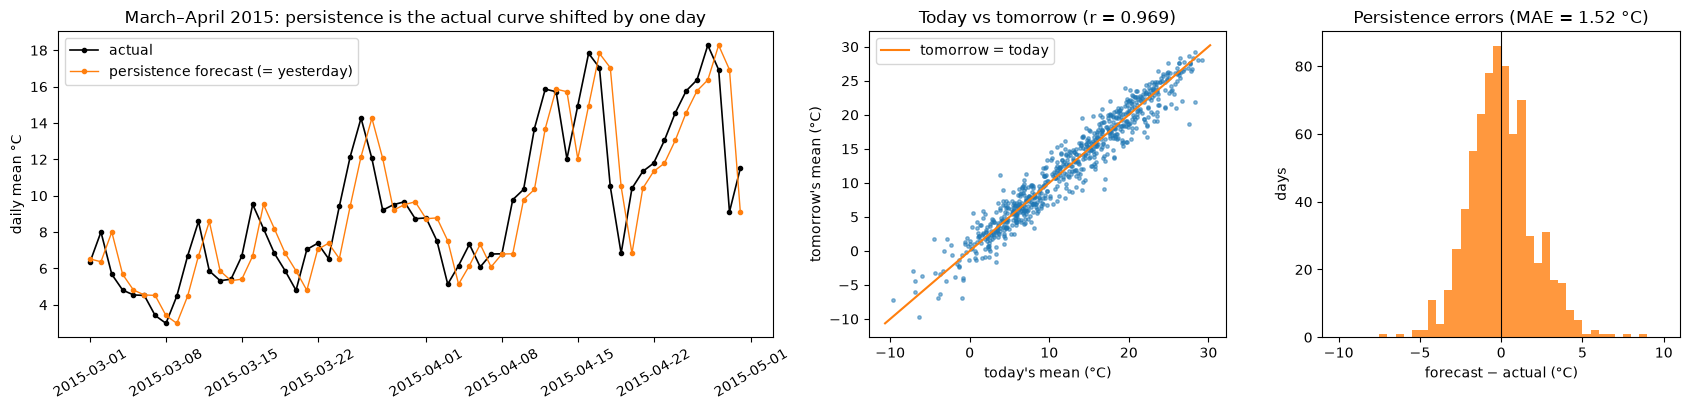

Persistence on validation: MAE 1.52 °C | within 1 °C on 42 % of days, within 2 °C on 72 % | off by more than 4 °C on 5.1 % of days
Climatology on validation: MAE 2.85 °C – knowing the season alone is much worse than knowing yesterday


In [24]:

d_va, y_va, p_va = ds.dates[va], ds.y[va], ds.last_mean[va]
err = p_va - y_va
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2), gridspec_kw={"width_ratios": [2, 1, 1]})

z = (d_va >= "2015-03-01") & (d_va <= "2015-04-30")
ax[0].plot(d_va[z], y_va[z], "k-o", ms=3, lw=1.2, label="actual")
ax[0].plot(d_va[z], p_va[z], "-o", color="tab:orange", ms=3, lw=1, label="persistence forecast (= yesterday)")
ax[0].set_title("March–April 2015: persistence is the actual curve shifted by one day"); ax[0].set_ylabel("daily mean °C")
ax[0].legend(); ax[0].tick_params(axis="x", rotation=30)

ax[1].scatter(p_va, y_va, s=6, alpha=0.5)
lim = [min(p_va.min(), y_va.min()) - 1, max(p_va.max(), y_va.max()) + 1]
ax[1].plot(lim, lim, color="tab:orange", lw=1.5, label="tomorrow = today")
ax[1].set_xlabel("today's mean (°C)"); ax[1].set_ylabel("tomorrow's mean (°C)")
ax[1].set_title(f"Today vs tomorrow (r = {np.corrcoef(p_va, y_va)[0, 1]:.3f})"); ax[1].legend()

ax[2].hist(err, bins=np.arange(-10, 10.5, 0.5), color="tab:orange", alpha=0.8)
ax[2].axvline(0, color="k", lw=0.8)
ax[2].set_title(f"Persistence errors (MAE = {np.abs(err).mean():.2f} °C)"); ax[2].set_xlabel("forecast − actual (°C)"); ax[2].set_ylabel("days")
plt.tight_layout(); plt.show()

a = np.abs(err)
print(f"Persistence on validation: MAE {a.mean():.2f} °C | within 1 °C on {100 * (a <= 1).mean():.0f} % of days, "
      f"within 2 °C on {100 * (a <= 2).mean():.0f} % | off by more than 4 °C on {100 * (a > 4).mean():.1f} % of days")
print(f"Climatology on validation: MAE {baselines['climatology (average for this day of year)']:.2f} °C – "
      f"knowing the season alone is much worse than knowing yesterday")


**The goal of the project follows from this:**
- Persistence is within 1 °C on 42 % of days and within 2 °C on 72 %. It's only badly wrong (> 4 °C) on about 5 % of days, right after sudden changes.
- Knowing the season alone (climatology, 2.85 °C) is much worse than knowing yesterday (1.52 °C).
- **Goal: beat persistence**, i.e. get below **1.52 °C on validation** and **1.43 °C on the 2016 test year**. A model that doesn't beat it has learned nothing useful.
- Persistence already gets the level right, so the model can only add value by **anticipating changes**. This motivated predicting the change (`target=delta`) and giving the model inputs that signal change: the pressure trend, wind direction and the evening temperature trend.

## 7. Systematic experiments

This section uses the course's building blocks; §7b goes beyond them.

**Starting point – the Class 2 tabular baseline:** standardised features → `Dense(64, relu)` → `Dense(32, relu)` → `Dense(1)`, Adam, MSE, batch 32, early stopping.

**Search procedure** (code below, settings in `config.yaml → search`). Following Class 2's "one parameter change per one test", each stage tries a few single changes on top of the current best configuration:

1. **target** – absolute temperature vs change from today
2. **input** – 3 daily rows vs 72 hourly rows (GRU / LSTM / Conv1D) vs both
3. **size** – units, dense head, bidirectional
4. **regularisation** – dropout, recurrent dropout, L2 (Class 2: only if overfitting)
5. **optimisation** – learning rate and batch size (Class 2: "usually sufficient to tune"), ReduceLROnPlateau (Class 3)
6. **loss** – MSE vs Huber
7. **extra inputs** – `Daily Summary` text, calendar removed
8. **second pass** – the input type and target re-tested with the tuned settings (added after the first full run; see the conclusions below)

Every configuration is trained with **3 seeds**, and we compare **mean ± std** of validation MAE. A change is kept only if it lowers the mean.

**Experiment log and caching.** Each training run is identified by its configuration, seed and fold, and appended to `runs/experiments.jsonl`. When the notebook runs again, finished runs are read from the log instead of retrained. The same configuration and seed give exactly the same result (§11), so this changes nothing in the results. It only means the full search (≈ 55 min of training) doesn't have to be repeated. **To retrain everything from scratch, delete `runs/experiments.jsonl`.**

In [25]:
LOG = RUNS / "experiments.jsonl"


def key_of(params, seed, fold):
    s = json.dumps(params, sort_keys=True) + f"|{seed}|{fold}"
    return hashlib.sha1(s.encode()).hexdigest()[:16]


def load_cache():
    if not LOG.exists():
        return {}
    return {r["key"]: r for r in map(json.loads, LOG.read_text().splitlines())}


CACHE = load_cache()
print(len(CACHE), "finished runs found in the log")


PREDS = RUNS / "preds"


def run(ds, params, seed, fold, phase, label, train_m, val_m, save_pred=False):
    k = key_of(params, seed, fold)
    if k in CACHE and (not save_pred or (PREDS / f"{k}.npy").exists()):
        return CACHE[k]
    t0 = time.time()
    res = train_eval(ds, params, seed, train_m, val_m, keep_pred=save_pred)
    if save_pred:
        PREDS.mkdir(exist_ok=True)
        np.save(PREDS / f"{k}.npy", res.pop("val_pred").astype("float32"))
    if k in CACHE:      # only the predictions were missing; keep the original log entry
        return CACHE[k]
    rec = {"key": k, "phase": phase, "label": label, "seed": seed, "fold": fold,
           "params": params, **res, "seconds": round(time.time() - t0, 1)}
    with LOG.open("a") as f:
        f.write(json.dumps(rec) + "\n")
    CACHE[k] = rec
    print(f"  {phase:8s} {label:45s} seed {seed:5d} fold {fold}: val MAE {res['val_mae']:.3f}  "
          f"({res['epochs_run']} ep, {rec['seconds']}s)", flush=True)
    return rec


def score(ds, cfg, params, phase, label):
    tr, va = ds.mask("train"), ds.mask("val")
    maes = [run(ds, params, s, "val", phase, label, tr, va)["val_mae"] for s in cfg["seeds"]]
    return float(np.mean(maes)), float(np.std(maes, ddof=1))


def describe(variant):
    return ", ".join(f"{k}={v}" for k, v in variant.items())

327 finished runs found in the log


**The greedy search** – stages and variants come from `config.yaml → search`.

In [26]:
best = dict(CONFIG["baseline"])
best_mean, best_std = score(ds, CONFIG, best, "search", "baseline")
search_steps = [{"stage": "baseline", "change": "Class 2 baseline", "mean": best_mean, "std": best_std,
                 "kept": True, "params": best}]
for stage in CONFIG["search"]:
    stage_best = None
    for v in stage["variants"]:
        p = {**best, **v}
        if p == best:
            continue
        m, s = score(ds, CONFIG, p, "search", f"{stage['name']}: {describe(v)}")
        search_steps.append({"stage": stage["name"], "change": describe(v), "mean": m, "std": s,
                             "kept": False, "params": p})
        if m < best_mean and (stage_best is None or m < stage_best[0]):
            stage_best = (m, s, p, len(search_steps) - 1)
    if stage_best:
        best_mean, best_std, best, i = stage_best
        search_steps[i]["kept"] = True
    print(f"after stage '{stage['name']}': {best_mean:.3f} ± {best_std:.3f} °C")
pd.DataFrame(search_steps).drop(columns="params").round(4).to_csv(RUNS / "search_steps.csv", index=False)

after stage 'target': 1.239 ± 0.007 °C
after stage 'input': 1.180 ± 0.031 °C
after stage 'size': 1.160 ± 0.017 °C
after stage 'regularisation': 1.140 ± 0.017 °C
after stage 'optimisation': 1.135 ± 0.019 °C
after stage 'loss': 1.135 ± 0.019 °C
after stage 'extra_inputs': 1.135 ± 0.019 °C
after stage 'second_pass_input': 1.104 ± 0.006 °C
after stage 'second_pass_target': 1.104 ± 0.006 °C


In [27]:
log = pd.read_json(RUNS / "experiments.jsonl", lines=True)
print(f"Training runs logged: {len(log)} | distinct configurations: {log['params'].astype(str).nunique()} | "
      f"total training time: {log['seconds'].sum() / 60:.1f} min")
steps = pd.read_csv(RUNS / "search_steps.csv")
steps

Training runs logged: 327 | distinct configurations: 49 | total training time: 270.2 min


,stage,change,mean,std,kept
0,baseline,Class 2 baseline,1.4783,0.0695,True
1,target,target=delta,1.2393,0.0073,True
2,input,"input=hourly, hourly_arch=gru",1.2410,0.0259,False
3,input,"input=hourly, hourly_arch=lstm",1.2736,0.0079,False
4,input,"input=hourly, hourly_arch=conv1d",1.2826,0.0339,False
5,input,"input=both, hourly_arch=gru",1.1989,0.0158,False
6,input,"input=daily, daily_arch=gru",1.1797,0.0306,True
7,size,units=16,1.1874,0.0032,False
8,size,units=64,1.1648,0.0153,False
9,size,dense=[],1.1777,0.0168,False


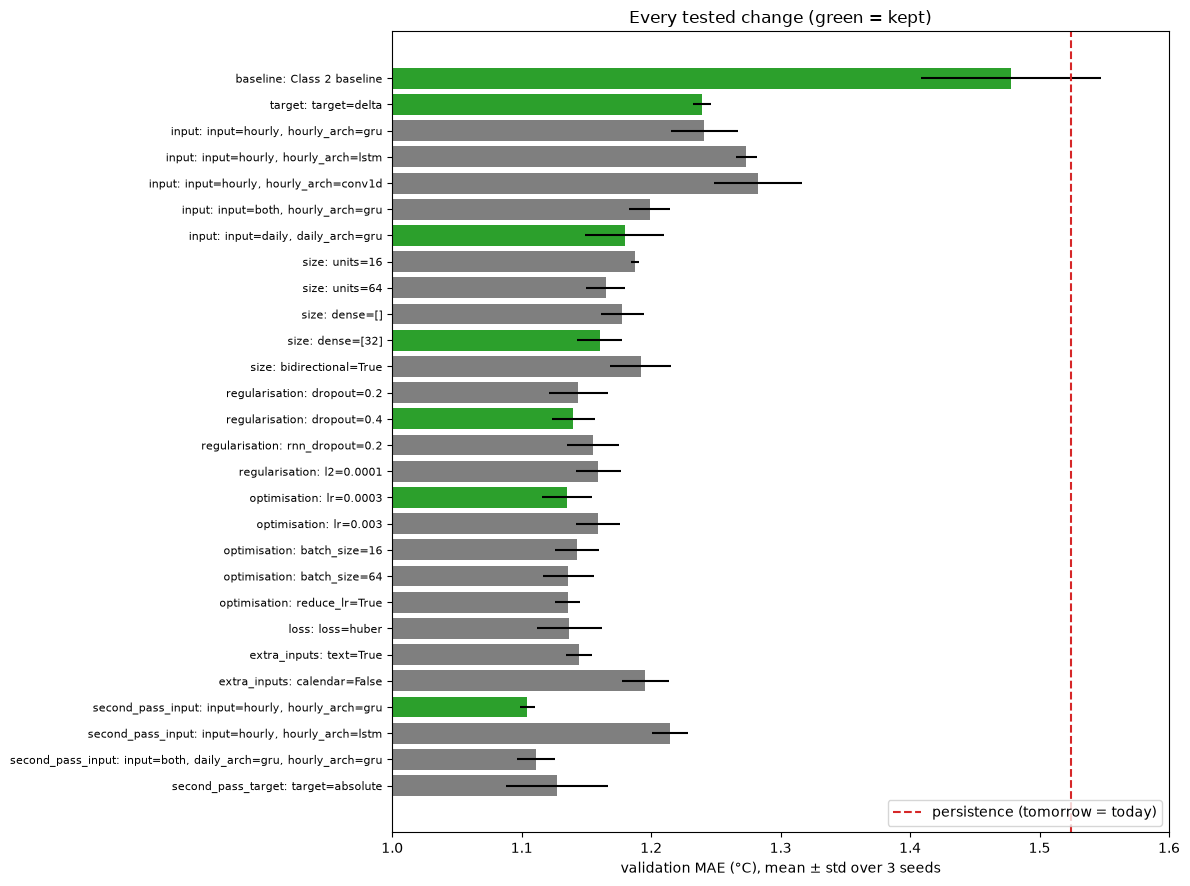

In [28]:
fig, ax = plt.subplots(figsize=(12, max(4, 0.32 * len(steps))))
yy = np.arange(len(steps))[::-1]
colors = ["tab:green" if k else "tab:gray" for k in steps["kept"]]
ax.barh(yy, steps["mean"], xerr=steps["std"], color=colors)
ax.set_yticks(yy, [f"{s}: {c}" for s, c in zip(steps["stage"], steps["change"])], fontsize=8)
for name, v in baselines.items():
    if v < 2:
        ax.axvline(v, color="tab:red", ls="--", label=name)
ax.set_xlim(1.0, max(1.6, steps["mean"].max() + 0.05)); ax.set_xlabel("validation MAE (°C), mean ± std over 3 seeds")
ax.set_title("Every tested change (green = kept)"); ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**What the search showed** (validation 2014–2015, mean of 3 seeds)
- **Predicting the change instead of the temperature** (`target=delta`, 1.478 → 1.239 °C) was the biggest single gain. The network no longer has to reproduce the seasonal level, which persistence already gives it; it only learns how tomorrow differs from today.
- **Reading the 3 days as a sequence with a GRU** (Class 2, `language.ipynb`) instead of flattening them: → 1.180 °C.
- **A smaller dense head** (`Dense(32)`) → 1.160 °C, and **dropout 0.4** → 1.140 °C (Class 2: "if overfitting → add Dropout"). With only ~2,900 training days, the network overfits quickly.
- **A lower learning rate** (0.0003) helped only marginally (1.135 °C). Batch size, ReduceLROnPlateau and the Huber loss made no real difference (≤ 0.005 °C, within seed noise), which matches the Class 2 note that sensible defaults usually work.
- **Changes that made things worse:** the `Daily Summary` text (1.144), removing the calendar (1.196), a bidirectional GRU, LSTM and Conv1D.
- **Second pass – a lesson about greedy search.** In the first pass, the hourly input lost because the input stage ran *before* dropout had been added (the bigger hourly branch overfit). Re-testing the input with the tuned settings, the **hourly GRU** reached 1.104 °C on validation. Results of a one-change-at-a-time search depend on the order of the stages, so it's worth revisiting early decisions at the end.
- **Validation and K-fold can disagree.** Validation (2 years) preferred hourly-only input, but K-fold over 10 years preferred **hourly + daily** (1.158 vs 1.175 °C, table below). K-fold averages over more data, so we trust it more.

### Robustness: blocked K-fold over years

The validation set covers only 2 years, and differences of a few hundredths of a degree could be noise. Following `regression.ipynb` (K-fold for small datasets), we re-evaluate the top configurations with **5 folds of whole years**: 2006–07, 2008–09, 2010–11, 2012–13 and 2014–15. Each fold is validated once while training on the rest, with 3 seeds per fold (15 runs per configuration).

We use blocks of years rather than random rows, because random rows would leak neighbouring days. The configuration with the best K-fold mean is the best **course-style** model. It becomes the reference for §7b, where we go beyond the course templates.

In [29]:
tried = {json.dumps(st["params"], sort_keys=True): st["mean"] for st in search_steps}
top = [json.loads(k) for k, _ in sorted(tried.items(), key=lambda kv: kv[1])[: CONFIG["cv"]["top_k"]]]
if best not in top:
    top.append(best)
cv_rows = []
for rank, p in enumerate(top):
    maes, epochs = [], []
    for years in CONFIG["cv"]["folds"]:
        fold_va = ds.mask("years", years)
        fold_tr = ds.mask("trainval") & ~fold_va
        for s in CONFIG["seeds"]:
            r = run(ds, p, s, f"{years[0]}-{years[-1]}", "cv", f"top{rank + 1}", fold_tr, fold_va)
            maes.append(r["val_mae"]); epochs.append(r["best_epoch"])
    cv_rows.append({"config": rank + 1,
                    "params": json.dumps({k: v for k, v in p.items() if CONFIG["baseline"].get(k) != v}),
                    "cv_mean": np.mean(maes), "cv_std": np.std(maes, ddof=1),
                    "median_best_epoch": int(np.median(epochs)), "full": p})
cv_df = pd.DataFrame(cv_rows)
cv_df.drop(columns="full").round(4).to_csv(RUNS / "cv.csv", index=False)
winner = cv_df.loc[cv_df["cv_mean"].idxmin()]
final_p, final_epochs = winner["full"], int(winner["median_best_epoch"])
(RUNS / "final_config.json").write_text(json.dumps({"params": final_p, "epochs": final_epochs}, indent=2))
print("K-fold winner:", winner["params"], "| epochs for the final training:", final_epochs)

K-fold winner: {"daily_arch": "gru", "dense": [32], "dropout": 0.4, "input": "both", "lr": 0.0003, "target": "delta"} | epochs for the final training: 71


In [30]:
cv = pd.read_csv(RUNS / "cv.csv")
cv

,config,params,cv_mean,cv_std,median_best_epoch
0,1,"{""daily_arch"": ""gru"", ""dense"": [32], ""dropout""...",1.1754,0.0471,97
1,2,"{""daily_arch"": ""gru"", ""dense"": [32], ""dropout""...",1.1578,0.0346,71
2,3,"{""daily_arch"": ""gru"", ""dense"": [32], ""dropout""...",1.1863,0.0390,62


### Feature ablation – which inputs matter?

Starting from the §7 K-fold winner, we remove one feature group at a time (from both the hourly and daily inputs) and retrain with 3 seeds. A bigger increase in error means the group matters more.

In [31]:
win_mean, win_std = score(ds, CONFIG, final_p, "ablation", "winner, nothing dropped")
abl_rows = [{"dropped": "(none)", "mean": win_mean, "std": win_std}]
for g in CONFIG["ablation"]:
    m, s = score(ds, CONFIG, {**final_p, "drop_groups": [g]}, "ablation", f"drop {g}")
    abl_rows.append({"dropped": g, "mean": m, "std": s})
abl = pd.DataFrame(abl_rows)
abl["change_vs_full"] = abl["mean"] - win_mean
abl.round(4).to_csv(RUNS / "ablation.csv", index=False)

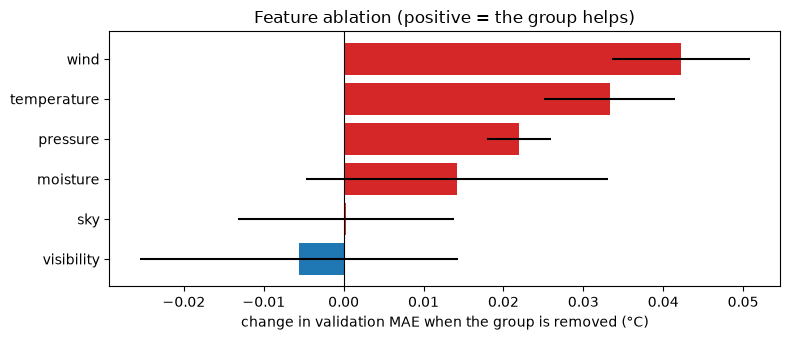

,dropped,mean,std,change_vs_full
0,(none),1.111,0.015,0.000
1,temperature,1.144,0.008,0.033
2,moisture,1.125,0.019,0.014
3,visibility,1.105,0.020,-0.006
4,pressure,1.133,0.004,0.022
5,wind,1.153,0.009,0.042
6,sky,1.111,0.014,0.000


In [32]:
abl = pd.read_csv(RUNS / "ablation.csv")
a = abl[abl["dropped"] != "(none)"].sort_values("change_vs_full")
plt.figure(figsize=(8, 3.5))
plt.barh(a["dropped"], a["change_vs_full"], xerr=a["std"], color=["tab:red" if v > 0 else "tab:blue" for v in a["change_vs_full"]])
plt.axvline(0, color="k", lw=0.8); plt.xlabel("change in validation MAE when the group is removed (°C)")
plt.title("Feature ablation (positive = the group helps)"); plt.tight_layout(); plt.show()
abl.round(3)

**Conclusions**
- **Wind** matters most (+0.042 °C when removed): wind direction brings warm or cold air from elsewhere. Next come **temperature history** (+0.033), **pressure** (+0.022 – falling pressure signals fronts) and **moisture** (+0.014).
- Removing **visibility** (−0.006) or the **sky** flags (cloudiness/fog/wind labels, 0.000) changes nothing beyond seed noise (std 0.01–0.02 °C). There's no evidence they help, but we kept them rather than tune further on the same validation set.

## 7b. Beyond the course templates – ideas tailored to weather data

So far the search only used building blocks from the classes. Here we try ideas designed for *this* problem. Each one is added on top of the §7 K-fold winner (the **reference**) and evaluated directly with **blocked K-fold** (5 folds × 3 seeds = 15 runs). The ideas and the reason for each are listed in `config.yaml → tailored`:

| Idea | Why it could help here |
|---|---|
| **Multi-task: mean + min + max** | min and max are driven by the same physics; extra supervision helps when we have only ~3,600 training days |
| **Predict the 24 hourly temperatures** of the next day (the mean is their average) | a richer target: the model has to get the whole daily curve right, not just one number |
| **Conv1D → GRU** on the hourly input | convolution summarises 3-hour blocks, so the GRU reads 24 steps instead of 72 |
| **Attention over the 72 hours** | a learned weight per hour lets the model focus on the most informative hours, not only the last GRU state |
| **Wider + stronger dropout** | more capacity, with dropout to keep overfitting in check |

**Is a difference real or just noise?** Every idea is trained on exactly the same folds and seeds as the reference, so we compare them **pair by pair**. We take the 15 differences, their mean, the standard error (SE) and *t* = mean / SE. As a rule of thumb, |t| > 2 means the difference is unlikely to be noise. **Rule:** ideas with t < −2 (clearly better) are combined into one model.

We also report the **seed ensemble**: in each fold, the average prediction of the 3 seeds. Averaging models trained with different seeds reduces the random part of their errors.

In [33]:
DEFAULTS_NEW = {"aux": "none", "attention": False}   # options added in §7b; their defaults = the old behaviour


def norm(p):
    """Drop new options that are at their default, so equivalent configurations share one log entry."""
    return {k: v for k, v in p.items() if not (k in DEFAULTS_NEW and DEFAULTS_NEW[k] == v)}


def cv_folds():
    for years in CONFIG["cv"]["folds"]:
        fva = ds.mask("years", years)
        yield f"{years[0]}-{years[-1]}", ds.mask("trainval") & ~fva, fva


def cv_eval(p, phase, label):
    """Blocked K-fold over years with 3 seeds per fold. Also scores the seed ensemble:
    the average of the 3 seeds' predictions in each fold."""
    p = norm(p)
    maes, epochs, ens = [], [], []
    for fold, ftr, fva in cv_folds():
        preds = []
        for s in CONFIG["seeds"]:
            r = run(ds, p, s, fold, phase, label, ftr, fva, save_pred=True)
            maes.append(r["val_mae"]); epochs.append(r["best_epoch"])
            preds.append(np.load(PREDS / f"{r['key']}.npy"))
        ens.append(np.mean(np.abs(np.mean(preds, 0) - ds.y[fva])))
    return {"cv_mean": np.mean(maes), "cv_std": np.std(maes, ddof=1), "runs": np.array(maes),
            "cv_ens_mean": np.mean(ens), "cv_ens_std": np.std(ens, ddof=1),
            "median_best_epoch": int(np.median(epochs)), "params": p}


def paired(a, b):
    """Paired comparison of two configurations on the same 15 (fold, seed) runs: mean difference b - a,
    its standard error and t = diff / SE. |t| > 2 is roughly a real difference, not noise."""
    d = b["runs"] - a["runs"]
    se = d.std(ddof=1) / np.sqrt(len(d))
    return d.mean(), se, d.mean() / se

In [34]:
base_p = norm(final_p)             # K-fold winner of the course-style search (§7)
rows = [{"model": "K-fold winner of §7 (reference)", **cv_eval(base_p, "tailored", "reference")}]
for t in CONFIG["tailored"]:
    rows.append({"model": t["name"], "why": t["why"], **cv_eval({**base_p, **t["change"]}, "tailored", t["name"])})

# Is each idea really better than the reference, or just noise? Paired comparison on the same folds and seeds.
for r in rows[1:]:
    r["paired diff"], r["SE"], r["t"] = paired(rows[0], r)
# Combine the ideas that are clearly better (t < -2).
winners = [t for t, r in zip(CONFIG["tailored"], rows[1:]) if r["t"] < -2]
if len(winners) > 1:
    combo = {**base_p}
    for t in winners:
        combo.update(t["change"])
    rows.append({"model": "combination: " + " + ".join(t["name"] for t in winners),
                 "why": "all ideas that improved K-fold individually", **cv_eval(combo, "tailored", "combination")})

    rows[-1]["paired diff"], rows[-1]["SE"], rows[-1]["t"] = paired(rows[0], rows[-1])
tailored = pd.DataFrame(rows)
tailored.drop(columns=["params", "runs"]).round(4).to_csv(RUNS / "tailored_cv.csv", index=False)
tailored[["model", "cv_mean", "cv_std", "cv_ens_mean", "paired diff", "SE", "t", "median_best_epoch"]].round(3)

,model,cv_mean,cv_std,cv_ens_mean,paired diff,SE,t,median_best_epoch
0,K-fold winner of §7 (reference),1.158,0.035,1.138,NaN,NaN,NaN,71
1,multi-task: predict mean + min + max,1.154,0.030,1.134,-0.004,0.005,-0.659,85
2,predict the 24 hourly temperatures,1.147,0.035,1.130,-0.010,0.004,-2.624,83
3,Conv1D -> GRU on the hourly input,1.174,0.027,1.142,0.016,0.004,3.615,54
4,attention over the 72 hours,1.148,0.031,1.125,-0.010,0.004,-2.849,70
5,wider network + stronger dropout,1.148,0.035,1.133,-0.010,0.007,-1.459,53
6,combination: predict the 24 hourly temperature...,1.145,0.033,1.123,-0.013,0.004,-3.020,91


**Conclusions**
- **Two ideas are clearly better than the reference:** predicting the **24 hourly temperatures** (−0.010 °C, t = −2.6) and **attention over the 72 hours** (−0.010 °C, t = −2.8). Their combination is the best model: **1.145 °C** K-fold, t = −3.0 vs the reference.
- **Conv1D → GRU is clearly worse** (+0.016 °C, t = +3.6): compressing the hourly series into 3-hour blocks throws away detail the GRU needs.
- **Multi-task min/max** (t = −0.7) and **wider + more dropout** (t = −1.5) are within noise, so we don't count them as improvements.
- **The seed ensemble helps every configuration:** averaging the 3 seeds lowers K-fold MAE by about 0.02 °C (e.g. combination: 1.145 → 1.123 °C).
- *Process note:* our first combination rule ("combine every idea that is better at all") was flawed. It also combined ideas within noise, and two of them overwrote each other (both change the output). We replaced it with the paired *t* rule above before running the final combination. Those runs stay in the log.

### Is deep learning needed? Classic machine-learning benchmarks

To justify a neural network at all, we compare it with two classic models on **the same inputs, target (change from today) and K-fold folds**. The first is Ridge regression, a linear model with L2 regularisation; its strength alpha is chosen by K-fold. The second is gradient-boosted trees (`HistGradientBoostingRegressor`), usually the strongest classic method on tabular data.

In [35]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_flat = np.concatenate([ds.X_daily.reshape(len(ds.y), -1), ds.X_hourly.reshape(len(ds.y), -1), ds.X_cal], 1)
delta = ds.y - ds.last_mean          # same target as the network: the change from today


def classic_cv(make_model, seeds):
    maes = []
    for fold, ftr, fva in cv_folds():
        for s in seeds:
            m = make_model(s).fit(X_flat[ftr], delta[ftr])
            maes.append(np.mean(np.abs(m.predict(X_flat[fva]) + ds.last_mean[fva] - ds.y[fva])))
    return np.mean(maes), np.std(maes, ddof=1) if len(maes) > 1 else 0.0


ccfg = CONFIG["classic"]
classic_rows = []
for a in ccfg["ridge_alphas"]:           # linear regression with L2; alpha picked by K-fold
    m, s = classic_cv(lambda seed: make_pipeline(StandardScaler(), Ridge(alpha=a)), [0])
    classic_rows.append({"model": f"Ridge regression (alpha={a})", "cv_mean": m, "cv_std": s})
m, s = classic_cv(lambda seed: HistGradientBoostingRegressor(**ccfg["hgb"], early_stopping=True,
                                                            validation_fraction=0.1, n_iter_no_change=30,
                                                            random_state=seed), CONFIG["seeds"])
classic_rows.append({"model": "Gradient boosting (HistGradientBoosting)", "cv_mean": m, "cv_std": s})
classic = pd.DataFrame(classic_rows)
classic.round(3).to_csv(RUNS / "classic_cv.csv", index=False)
classic.round(3)

,model,cv_mean,cv_std
0,Ridge regression (alpha=1.0),1.368,0.047
1,Ridge regression (alpha=10.0),1.342,0.042
2,Ridge regression (alpha=100.0),1.295,0.040
3,Ridge regression (alpha=1000.0),1.288,0.034
4,Ridge regression (alpha=3000.0),1.336,0.040
5,Ridge regression (alpha=10000.0),1.408,0.053
6,Ridge regression (alpha=30000.0),1.477,0.068
7,Gradient boosting (HistGradientBoosting),1.221,0.038


**Conclusions**
- **Gradient boosting reaches 1.221 °C** and the best **Ridge regression 1.288 °C** (alpha = 1000; the grid brackets the optimum). Both clearly beat persistence (1.52 on validation), so the inputs carry real signal.
- **The neural network is better than both** (1.145 °C single model, 1.123 °C seed ensemble, on the same folds). The GRUs read the 72 hours in order, so they can use the *shape* of the recent temperature curve. The tree and linear models only see 1,000+ separate numbers. This justifies using deep learning for this problem.

## 7c. Final choice and why every part of the model is there

**Final choice:** the configuration with the **lowest K-fold MAE** among everything evaluated with K-fold (§7 and §7b). We use the **seed ensemble** as the final predictor if it beats single models on K-fold. The model is then trained for the median best epoch across the K-fold runs.

In [36]:
# Final choice = lowest K-fold MAE among everything evaluated with K-fold (§7 + §7b).
# The seed ensemble is used as the final predictor if it beats single models on K-fold.
cands = [{"model": f"§7 top{r['config']}", **r, "params": norm(r["full"])} for r in cv_rows]
cands += tailored.to_dict("records")
best_c = min(cands, key=lambda r: r["cv_mean"])
final_p, final_epochs = best_c["params"], int(best_c["median_best_epoch"])
final_res = cv_eval(final_p, "tailored", "final")
use_ensemble = final_res["cv_ens_mean"] < final_res["cv_mean"]
(RUNS / "final_config.json").write_text(json.dumps(
    {"params": final_p, "epochs": final_epochs, "seed_ensemble": bool(use_ensemble)}, indent=2))
print("Final model:", best_c["model"])
print("Changes from the Class 2 baseline:", {k: v for k, v in final_p.items() if CONFIG["baseline"].get(k) != v})
print(f"K-fold MAE: single model {final_res['cv_mean']:.3f} ± {final_res['cv_std']:.3f} °C | "
      f"seed ensemble {final_res['cv_ens_mean']:.3f} ± {final_res['cv_ens_std']:.3f} °C")
print("Final predictor:", "average of the 3 seeds (seed ensemble)" if use_ensemble else "single models")

Final model: combination: predict the 24 hourly temperatures + attention over the 72 hours
Changes from the Class 2 baseline: {'daily_arch': 'gru', 'dense': [32], 'dropout': 0.4, 'input': 'both', 'lr': 0.0003, 'target': 'delta', 'aux': 'hourly24', 'attention': True}
K-fold MAE: single model 1.145 ± 0.033 °C | seed ensemble 1.123 ± 0.038 °C
Final predictor: average of the 3 seeds (seed ensemble)


### Architecture justification

We remove or replace **one component at a time** from the final model and run the full K-fold again. The cost of removing a component is the paired difference to the final model, with its standard error and *t*. A clearly positive cost (t > 2) means the component earns its place.

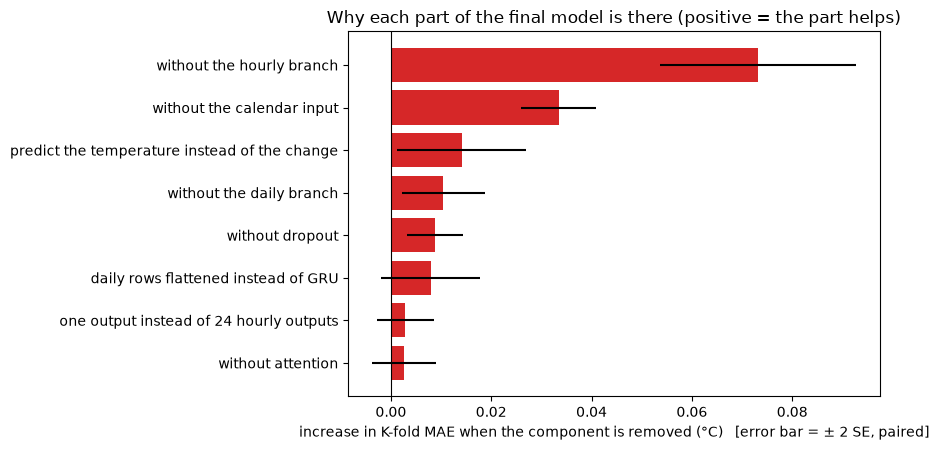

,variant,cv_mean,cv_std,cost of removing (°C),SE,t
0,final model (nothing removed),1.145,0.033,NaN,NaN,NaN
1,without the hourly branch,1.218,0.048,0.073,0.010,7.505
2,without the daily branch,1.155,0.037,0.010,0.004,2.521
3,predict the temperature instead of the change,1.159,0.045,0.014,0.006,2.206
4,daily rows flattened instead of GRU,1.153,0.041,0.008,0.005,1.598
5,without dropout,1.154,0.034,0.009,0.003,3.114
6,without the calendar input,1.178,0.040,0.033,0.004,8.980
7,one output instead of 24 hourly outputs,1.148,0.031,0.003,0.003,0.999
8,without attention,1.147,0.035,0.003,0.003,0.825


In [37]:
just_rows = [{"variant": "final model (nothing removed)", **final_res}]
for j in CONFIG["justification"]:
    p = norm({**final_p, **j["change"]})
    if p == final_p:          # component not part of the final model -> nothing to remove
        continue
    just_rows.append({"variant": j["name"], **cv_eval(p, "justify", j["name"])})
for r in just_rows[1:]:
    r["cost of removing (°C)"], r["SE"], r["t"] = paired(final_res, r)
just = pd.DataFrame(just_rows)
just.drop(columns=["params", "runs"]).round(4).to_csv(RUNS / "justification_cv.csv", index=False)

j = just.iloc[1:].sort_values("cost of removing (°C)")
plt.figure(figsize=(9, 0.45 * len(j) + 1))
plt.barh(j["variant"], j["cost of removing (°C)"], xerr=2 * j["SE"],
         color=["tab:red" if v > 0 else "tab:blue" for v in j["cost of removing (°C)"]])
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("increase in K-fold MAE when the component is removed (°C)   [error bar = ± 2 SE, paired]")
plt.title("Why each part of the final model is there (positive = the part helps)")
plt.tight_layout(); plt.show()
just[["variant", "cv_mean", "cv_std", "cost of removing (°C)", "SE", "t"]].round(3)

**What each part contributes** (K-fold, paired; cost = how much worse the model gets without it)
- **Hourly branch: +0.073 °C (t = 7.5)** – by far the most important part. The detailed last 72 hours carry most of the information.
- **Calendar input: +0.033 °C (t = 9.0)** – the model needs to know the season, e.g. how fast it cools in autumn.
- **Dropout: +0.009 °C (t = 3.1)**, **daily branch: +0.010 °C (t = 2.5)**, **predicting the change: +0.014 °C (t = 2.2)** – each clearly earns its place.
- **GRU on the daily rows instead of flattening: +0.008 °C (t = 1.6)** – likely helps, but not clearly.
- **24 hourly outputs (+0.003, t = 1.0)** and **attention (+0.003, t = 0.8)** – *inside the combination*, each adds very little. On its own, each clearly improved on the reference (§7b). Together they overlap: both help the model focus on the recent part of the daily cycle. **Either one alone gives almost the same result**, so a simpler model is equally defensible. We keep the combination because it won under the selection rule fixed in advance.

## 8. Live demonstration: course baseline vs final model

These two runs are re-trained here (seed 123) to show the difference live. All other numbers come from the logged runs.

In [38]:
print("Final configuration (differences from the baseline):")
print({k: v for k, v in final_p.items() if CONFIG["baseline"].get(k) != v})

demo = {}
for name, p in [("Class 2 baseline", CONFIG["baseline"]), ("final configuration", final_p)]:
    res, model, prep, hist = train_eval(ds, p, 123, tr, va, return_model=True)
    demo[name] = (model, prep, hist)
    print(f"{name:20s}: validation MAE {res['val_mae']:.3f} °C (best epoch {res['best_epoch']})")

Final configuration (differences from the baseline):
{'daily_arch': 'gru', 'dense': [32], 'dropout': 0.4, 'input': 'both', 'lr': 0.0003, 'target': 'delta', 'aux': 'hourly24', 'attention': True}


E0000 00:00:1793263777.357877 22627971 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


Class 2 baseline    : validation MAE 1.476 °C (best epoch 17)


final configuration : validation MAE 1.093 °C (best epoch 82)


E0000 00:00:1793263828.320276 22627971 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


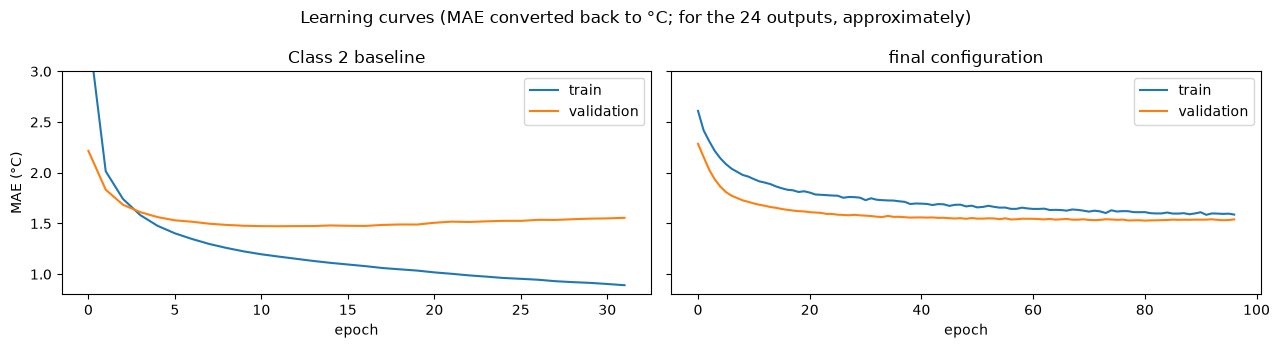

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5), sharey=True)
for a, (name, (_, prep, hist)) in zip(ax, demo.items()):
    a.plot(np.array(hist.history["mae"]) * np.mean(prep.sd_y), label="train")
    a.plot(np.array(hist.history["val_mae"]) * np.mean(prep.sd_y), label="validation")
    a.set_title(name); a.set_xlabel("epoch"); a.legend()
ax[0].set_ylabel("MAE (°C)"); ax[0].set_ylim(0.8, 3)
plt.suptitle("Learning curves (MAE converted back to °C; for the 24 outputs, approximately)"); plt.tight_layout(); plt.show()

## 9. Final architecture

In [40]:
demo["final configuration"][0].summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ hourly (InputLayer) │ (None, 72, 13)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ [(None, 72, 32),  │      4,512 │ hourly[0][0]      │
│                     │ (None, 32)]       │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 72, 1)     │         33 │ gru_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ softmax (Softmax)   │ (None, 72, 1)     │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dot (Dot)           │ (None, 1, 32)     │          0 │ softmax[0][0],    │
│                     │                   │            │ gru_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ daily (InputLayer)  │ (None, 3, 16)     │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_1 (Flatten) │ (None, 32)        │          0 │ dot[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 32)        │      4,800 │ daily[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 64)        │          0 │ flatten_1[0][0],  │
│ (Concatenate)       │                   │            │ gru_1[0][1]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cal (InputLayer)    │ (None, 2)         │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 98)        │          0 │ gru[0][0],        │
│ (Concatenate)       │                   │            │ concatenate_1[0]… │
│                     │                   │            │ cal[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 32)        │      3,168 │ concatenate_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32)        │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 24)        │        792 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 39,917 (155.93 KB)

 Trainable params: 13,305 (51.97 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 26,612 (103.96 KB)

**Final network (functional API, three inputs, 13,305 trainable parameters)**

```
hourly : 72 h × 13 features ─► GRU(32, every step) ─┬─► attention pooling ─┐
                                                    └─► last GRU state ─────┤
daily  :  3 d × 16 features ─► GRU(32) ─────────────────────────────────────┼─► Concatenate ─► Dense(32, relu) ─► Dropout(0.4) ─► Dense(24)
calendar: day of year (sin, cos) ───────────────────────────────────────────┘
```

- **Output: 24 numbers.** These are the next day's hourly temperatures, each as a change from today's daily mean (standardised). The prediction for the next day's mean is their average, plus today's mean.
- **Attention pooling:** a `Dense(1)` layer scores each of the 72 GRU outputs, softmax turns the scores into weights, and the weighted sum is concatenated with the last GRU state.
- **Why GRUs:** the inputs are time-ordered sequences (Class 2, `language.ipynb`). A GRU has fewer parameters than an LSTM and did better here (hourly GRU 1.104 vs LSTM 1.214 °C on validation).
- **Loss:** MSE. Huber made no difference (§7). **Optimiser:** Adam with lr 0.0003, batch 32, early stopping (patience 15) during the search. The final models are trained for **91 epochs** (median best epoch across K-fold runs) on 2006–2015.
- **Final predictor:** the **average of the 3 seed models**, which K-fold showed to be better than any single model (§7c).
- Every component is justified by the K-fold ablation in §7c.

## 10. Final result on the test set (2016)

The final model is retrained from scratch on **2006–2015** (train + validation, as in the "training the final model" step of `regression.ipynb`) for the number of epochs chosen by K-fold. This is done with each of the 3 seeds, and the final prediction is their average (seed ensemble, §7c). It is evaluated on 2016, which was never used for any modelling decision.

> **Every use of the test set, for transparency.** Before the final model, the test year was evaluated twice: with the first-pass model of §7 and with the second-pass model. Both used the rain feature that we later removed (Issue 8). Neither result was used to choose anything; all choices came from validation and K-fold. Both are listed below.

In [41]:
if CONFIG["run_test"]:
    tv, te = ds.mask("trainval"), ds.mask("test")
    out = RUNS / "final"; out.mkdir(exist_ok=True)
    preds, maes = [], []
    for s in CONFIG["seeds"]:
        _, model, prep, _ = train_eval(ds, final_p, s, tv, epochs=final_epochs,
                                       log_csv=out / f"history_seed_{s}.csv", return_model=True)
        model.save(out / f"model_seed_{s}.keras")
        pred = predict_celsius(model, prep, te)
        preds.append(pred); maes.append(float(np.mean(np.abs(pred - ds.y[te]))))
    ens = np.mean(preds, axis=0)
    y_te, dates_te = ds.y[te], ds.dates[te]
    clim_tv = (pd.Series(ds.y[tv], index=ds.dates[tv].dayofyear).groupby(level=0).mean()
               .reindex(range(1, 367)).interpolate().rolling(15, center=True, min_periods=1).mean())
    summary = {
        "test_mae_mean": float(np.mean(maes)), "test_mae_std": float(np.std(maes, ddof=1)),
        "test_mae_per_seed": maes,
        "test_mae_seed_ensemble": float(np.mean(np.abs(ens - y_te))),
        "test_rmse_seed_ensemble": float(np.sqrt(np.mean((ens - y_te) ** 2))),
        "test_persistence_mae": float(np.mean(np.abs(ds.last_mean[te] - y_te))),
        "test_climatology_mae": float(np.mean(np.abs(clim_tv.loc[dates_te.dayofyear].to_numpy() - y_te))),
        "epochs": final_epochs, "params": final_p,
    }
    (out / "test_summary.json").write_text(json.dumps(summary, indent=2))
    pd.DataFrame({"date": dates_te, "actual": y_te, "ensemble": ens, "persistence": ds.last_mean[te],
                  **{f"seed_{s}": p for s, p in zip(CONFIG["seeds"], preds)}}).to_csv(out / "test_predictions.csv", index=False)
else:
    print("run_test is false in config.yaml – the test set is not used.")

E0000 00:00:1793263880.613295 22627971 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


E0000 00:00:1793263932.634929 22627971 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


E0000 00:00:1793263984.263474 22627971 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_16}}


In [42]:
test = json.loads((RUNS / "final" / "test_summary.json").read_text())
tp = pd.read_csv(RUNS / "final" / "test_predictions.csv", parse_dates=["date"])
print(f"FINAL MODEL – average of the 3 seeds: test MAE {test['test_mae_seed_ensemble']:.3f} °C, "
      f"RMSE {test['test_rmse_seed_ensemble']:.3f} °C")
print(f"  single models (3 seeds): {test['test_mae_mean']:.3f} ± {test['test_mae_std']:.3f} °C  "
      f"(per seed: {', '.join(f'{v:.3f}' for v in test['test_mae_per_seed'])})")
print(f"Persistence baseline : test MAE {test['test_persistence_mae']:.3f} °C")
print(f"Climatology baseline : test MAE {test['test_climatology_mae']:.3f} °C")
print(f"Improvement over persistence: {100 * (1 - test['test_mae_seed_ensemble'] / test['test_persistence_mae']):.0f} %")
print("\nEarlier evaluations of the test set (with the removed rain feature, not used for any decision):")
for name in ["test_eval_1_first_pass", "test_eval_2_second_pass"]:
    old = json.loads((RUNS / "history_with_rain_feature" / name / "test_summary.json").read_text())
    print(f"  {name}: single models {old['test_mae_mean']:.3f} ± {old['test_mae_std']:.3f} °C, "
          f"seed average {old['test_mae_seed_ensemble']:.3f} °C")

FINAL MODEL – average of the 3 seeds: test MAE 1.160 °C, RMSE 1.508 °C
  single models (3 seeds): 1.178 ± 0.010 °C  (per seed: 1.167, 1.183, 1.185)
Persistence baseline : test MAE 1.428 °C
Climatology baseline : test MAE 2.535 °C
Improvement over persistence: 19 %

Earlier evaluations of the test set (with the removed rain feature, not used for any decision):
  test_eval_1_first_pass: single models 1.287 ± 0.014 °C, seed average 1.256 °C
  test_eval_2_second_pass: single models 1.269 ± 0.048 °C, seed average 1.232 °C


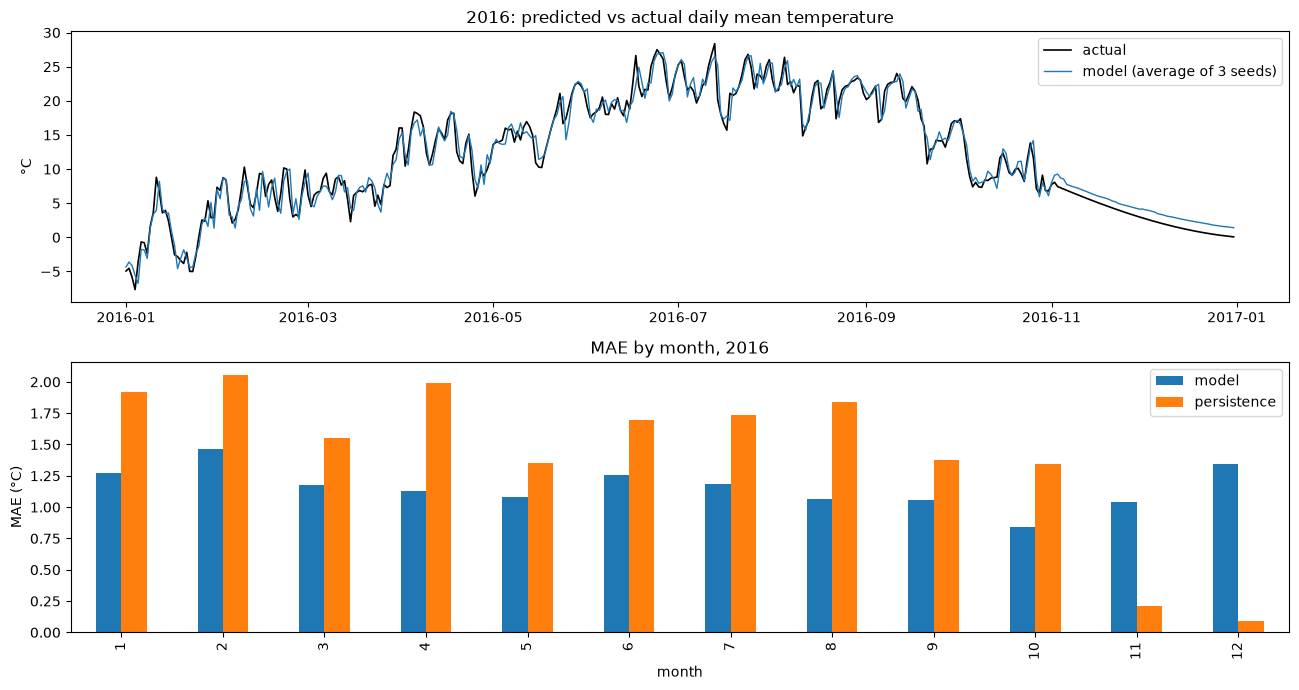

Five largest errors (note the size of the day-to-day change):


/var/folders/kz/jyvj1ds150g0xkk5bcx5gg7r0000gn/T/ipykernel_91116/1841268091.py:13: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  big.reindex(big["error"].abs().sort_values(ascending=False).index).head(5)[["date", "actual", "ensemble", "persistence", "error", "change"]].round(1)


,date,actual,ensemble,persistence,error,change
248,2016-09-05,16.8,22.4,22.2,5.6,-5.3
44,2016-02-14,9.4,3.9,6.5,-5.4,2.9
195,2016-07-14,20.1,25.2,28.4,5.1,-8.3
10,2016-01-11,8.8,3.9,3.6,-4.9,5.2
54,2016-02-24,5.6,10.0,10.0,4.4,-4.4


In [43]:
fig, ax = plt.subplots(2, 1, figsize=(13, 7))
ax[0].plot(tp["date"], tp["actual"], label="actual", lw=1.2, color="k")
ax[0].plot(tp["date"], tp["ensemble"], label="model (average of 3 seeds)", lw=1)
ax[0].set_title("2016: predicted vs actual daily mean temperature"); ax[0].set_ylabel("°C"); ax[0].legend()
err_m = (tp["ensemble"] - tp["actual"]).abs(); err_p = (tp["persistence"] - tp["actual"]).abs()
monthly = pd.DataFrame({"model": err_m.groupby(tp["date"].dt.month).mean(),
                        "persistence": err_p.groupby(tp["date"].dt.month).mean()})
monthly.plot.bar(ax=ax[1]); ax[1].set_title("MAE by month, 2016"); ax[1].set_ylabel("MAE (°C)"); ax[1].set_xlabel("month")
plt.tight_layout(); plt.show()

big = tp.assign(error=tp["ensemble"] - tp["actual"], change=tp["actual"] - tp["persistence"])
print("Five largest errors (note the size of the day-to-day change):")
big.reindex(big["error"].abs().sort_values(ascending=False).index).head(5)[["date", "actual", "ensemble", "persistence", "error", "change"]].round(1)


### Goal check: did we beat "tomorrow = today"?

The goal set in §6 was to beat persistence. The chart compares all approaches on 2016. The table below shows **where** the model gains: we split the test days by how much the temperature actually changed from the day before.


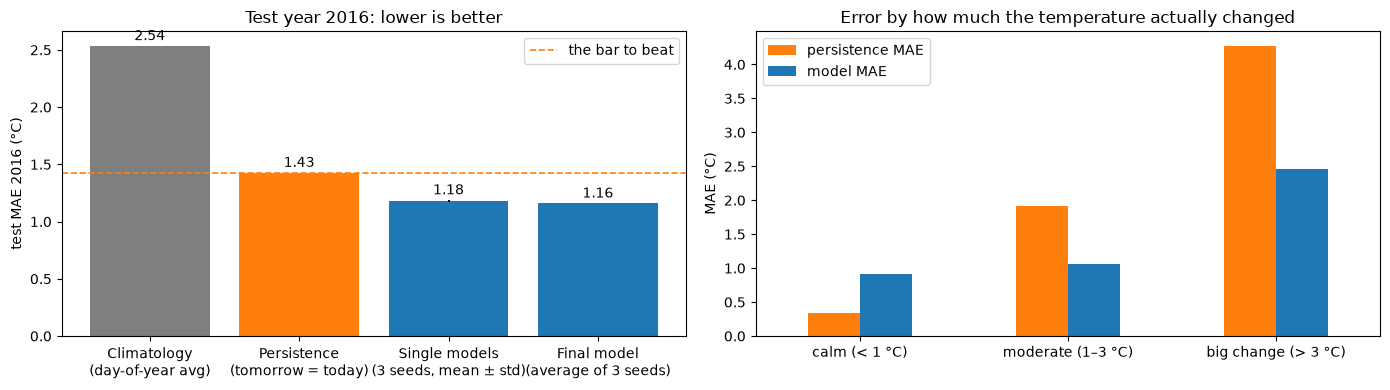

Model beats persistence by 0.25 °C (17 %); with the seed average by 0.27 °C (19 %)
Model closer to the truth than persistence on 56 % of the 366 days


,days,persistence MAE,model MAE
calm (< 1 °C),181,0.34,0.92
moderate (1–3 °C),140,1.91,1.06
big change (> 3 °C),45,4.27,2.47


In [44]:

chg = (tp["actual"] - tp["persistence"]).abs()
err_model = (tp["ensemble"] - tp["actual"]).abs()
err_pers = (tp["persistence"] - tp["actual"]).abs()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
names = ["Climatology\n(day-of-year avg)", "Persistence\n(tomorrow = today)", "Single models\n(3 seeds, mean ± std)", "Final model\n(average of 3 seeds)"]
vals = [test["test_climatology_mae"], test["test_persistence_mae"], test["test_mae_mean"], test["test_mae_seed_ensemble"]]
bars = ax[0].bar(names, vals, yerr=[0, 0, test["test_mae_std"], 0], color=["tab:gray", "tab:orange", "tab:blue", "tab:blue"])
ax[0].axhline(test["test_persistence_mae"], color="tab:orange", ls="--", lw=1.2, label="the bar to beat")
for b, v, e in zip(bars, vals, [0, 0, test["test_mae_std"], 0]):
    ax[0].text(b.get_x() + b.get_width() / 2, v + e + 0.05, f"{v:.2f}", ha="center")
ax[0].set_ylabel("test MAE 2016 (°C)"); ax[0].set_title("Test year 2016: lower is better"); ax[0].legend()

bins = pd.cut(chg, [0, 1, 3, 20], labels=["calm (< 1 °C)", "moderate (1–3 °C)", "big change (> 3 °C)"], include_lowest=True)
by = pd.DataFrame({"days": bins.value_counts().sort_index(),
                   "persistence MAE": err_pers.groupby(bins, observed=False).mean(),
                   "model MAE": err_model.groupby(bins, observed=False).mean()})
by[["persistence MAE", "model MAE"]].plot.bar(ax=ax[1], color=["tab:orange", "tab:blue"], rot=0)
ax[1].set_title("Error by how much the temperature actually changed"); ax[1].set_ylabel("MAE (°C)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

print(f"Model beats persistence by {test['test_persistence_mae'] - test['test_mae_mean']:.2f} °C "
      f"({100 * (1 - test['test_mae_mean'] / test['test_persistence_mae']):.0f} %); with the seed average by "
      f"{test['test_persistence_mae'] - test['test_mae_seed_ensemble']:.2f} °C "
      f"({100 * (1 - test['test_mae_seed_ensemble'] / test['test_persistence_mae']):.0f} %)")
print(f"Model closer to the truth than persistence on {100 * (err_model < err_pers).mean():.0f} % of the 366 days")
by.round(2)


**Goal reached**
- The final model beats persistence on the unseen year: **1.160 °C vs 1.428 °C (−19 %)**. Single models without seed averaging get 1.178 ± 0.010 °C (−17 %).
- It's closer to the truth than persistence on **56 % of days**. The gain doesn't come from being better every day; it comes from **far fewer large misses**.
- On the 45 days with a **big change (> 3 °C)**, the model's error is 2.47 °C vs 4.27 °C for persistence. On moderate days it's 1.06 vs 1.91 °C.
- On **calm days** persistence wins (0.34 vs 0.92 °C): the model sometimes predicts a change that doesn't come. Note that the days are grouped by the actual change, which *is* persistence's error, so calm days favour persistence by construction. The split shows *where* the model adds value; it isn't a fair head-to-head per group.

**Conclusions**
- On data it had never seen (2016), the final model is **1.16 °C off on average**: 19 % better than persistence, and less than half the climatology error.
- The test error is close to the **K-fold estimate (1.12 °C** for the seed ensemble). K-fold over 10 years was a realistic estimate of performance on new data.
- **Most of the largest errors come on days of sudden change.** Four of the five largest errors fall on days when the mean changed by 3–8 °C (e.g. 14 July 2016: −8.3 °C, a cold front). The model only sees one weather station, so it can't see a front approaching from elsewhere, and more tuning wouldn't fix that.
- **The earlier models** were evaluated on 2016 with the removed rain feature: 1.256 and 1.232 °C (seed average). Two things improved since: the rain fix (Issue 8) and the tailored architecture (§7b). These results were not used for any decision.

## 11. Reproducibility check (Class 1, step 7)

Training the same configuration twice with the same seed must give exactly the same result.

In [45]:
p_fast = CONFIG["baseline"]
a = train_eval(ds, p_fast, 1, tr, va)["val_mae"]
b = train_eval(ds, p_fast, 1, tr, va)["val_mae"]
print("Reproducible:", a == b, a, b)

Reproducible: True 1.3554575443267822 1.3554575443267822


## 12. Summary, problems and lessons

**Result:** a two-branch GRU network with attention and a 24-hour output, averaged over 3 seeds, predicts the next day's mean temperature with **MAE 1.16 °C** on the unseen year 2016. That's **19 % better than "tomorrow = today"** (1.43 °C) and more than twice as good as the seasonal average (2.54 °C). It also beats gradient boosting and Ridge regression on the same K-fold folds.

**Problems we found**
1. Data quality: unsorted rows, duplicated rows, a constant column, impossible zeros in pressure and humidity, mixed time zones, a misleading `Precip Type` column, and **rain labels that exist only in 2012 and 2016** (§2–3).
2. Choosing the target: the brief doesn't define "temperature for the next day", so we chose the daily mean.
3. Temporal leakage risk: we used a time-based split and blocked K-fold instead of random splits.
4. Untrained output scale: the first attempt couldn't learn the ~12 °C level quickly enough. We fixed it by scaling the target, as in `regression.ipynb`.
5. A feature with zero spread in one training fold blew up scaling. This is how we found the rain problem; scaling is now safe (`safe_std`).
6. Greedy search order: the hourly input was rejected too early and only won after re-testing (§7).
7. A 2-year validation set is noisy: it ranked configurations differently from K-fold, and it can't separate differences below ~0.01 °C. Paired comparisons on K-fold can.

**Lessons**
- Always compare against simple baselines. Persistence is very hard to beat for weather.
- Predicting the change, giving the model the hourly sequence, and the calendar mattered far more than tuning learning rate or batch size.
- Ideas that each help on their own may overlap, so check what each part adds *inside* the final model.
- One weather station sets a limit: sudden fronts come from outside the data.

**Possible next steps:** data from neighbouring stations (to see fronts coming), predicting next-day min/max as well, and a longer input history (if the brief allowed more than 3 days).

### How to reproduce
```bash
python3.12 -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt      # exact versions
jupyter lab weather_forecast.ipynb    # run all cells top to bottom
# finished runs are reused from runs/experiments.jsonl; delete it to retrain everything (~1 h on CPU)
```

## Use of AI tools

Required by `Grading.md`. *To be reviewed and completed by the team:* the code (data pipeline, experiment search, model code) and the first draft of the explanations were produced with **Claude Code (Anthropic)**. The team reviewed every part. We must be able to explain every architectural choice, loss function and line of code; anything we can't explain gets removed.